# Jawaban Evaluasi Praktikum Pertemuan 1-4 Computer Vision
## Studi Kasus SIMUTEH: Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra

Program Studi Teknik Informatika, Universitas Muhammadiyah Sukabumi, TA 2026/2027

**Cara memakai notebook ini di Google Colab**
1. Buka notebook di Google Colab, lalu isi identitas pada sel pertama (NIM menentukan SEED).
2. Pilih menu **Runtime > Run all**. Seluruh kode, termasuk pembuatan dataset sintetis, berjalan otomatis tanpa memerlukan unggahan berkas atau foto apa pun.
3. Hasil gambar dan tabel tersimpan di folder `hasil/`. Folder kerja dapat diunduh pada sel terakhir.

**Catatan:** seluruh kegiatan hanya memakai dataset sintetis bawaan. Jawaban analisis ditulis berdasarkan keluaran dengan **SEED = 1234**. Dengan SEED lain angka akan berbeda, tetapi pola hasil dan kesimpulannya seharusnya sama. Bila Anda memakai SEED lain, sesuaikan angka pada jawaban dengan keluaran Anda sendiri.

## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Moch. Abdi Hafidz Fadilah"
NIM   = "2230511051"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7A"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2230511051
SEED         : 1051


In [ ]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1051          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [ ]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [ ]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [ ]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  5.14  1.67  2.11  4.07  4.63  5.68  8.84
ringan   20.0  0.38  0.22  0.09  0.21  0.37  0.59  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 1. Lingkungan Kerja dan Formulasi Masalah
### Kode 1.1 Uji lingkungan dan struktur larik citra

OpenCV 5.0.0 | NumPy 2.4.6 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 249
piksel (y=100, x=200) dalam urutan BGR: [172 170 201]


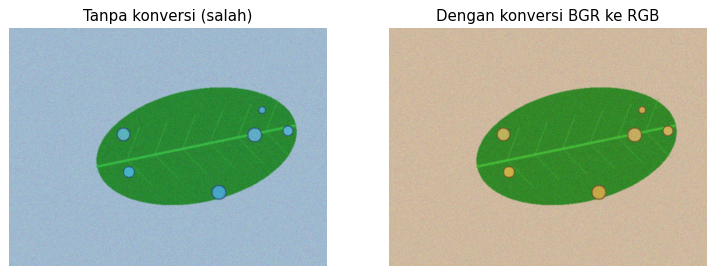

Potongan 5x5 nilai keabuan di sekitar (y, x) = (247, 396)
[[ 98  94  97 100  96]
 [102 110 104  94 101]
 [109  94  97 101 102]
 [ 98 102 111 101 109]
 [ 96  99 100  98  95]]


In [ ]:
import skimage
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.axis("off")
plt.savefig("../hasil/b1_bgr_rgb.png", bbox_inches="tight"); plt.show()

# contoh semantic gap: potongan 5 x 5 kanal keabuan di sekitar bercak
md0 = cv2.imread("../data/sintetis/mask_bercak/teh_041.png", 0)
ys, xs = np.where(md0 > 0)
cy, cx = int(ys.mean()), int(xs.mean())
gray0 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Potongan 5x5 nilai keabuan di sekitar (y, x) =", (cy, cx))
print(gray0[cy-2:cy+3, cx-2:cx+3])

### Problem Statement SIMUTEH

> Bagi **petugas sortir kelompok tani teh rakyat di Kabupaten Sukabumi** yang menghadapi **penilaian mutu daun secara manual yang lambat dan tidak seragam, terutama saat cahaya tidak merata dan bercak cacar daun masih kecil**, kami membangun **SIMUTEH, sistem pemeriksaan mutu daun berbasis citra** yang menerima **foto daun di atas nampan sortir dari kamera telepon genggam** dan menghasilkan **kelas mutu (Sehat, Bercak Ringan, Bercak Berat) beserta persentase luas bercak terhadap luas daun**, sehingga **penyortiran lebih cepat, lebih seragam, dan keputusan akhir petugas didukung bukti yang terukur**.

### Diagram Pipeline SIMUTEH

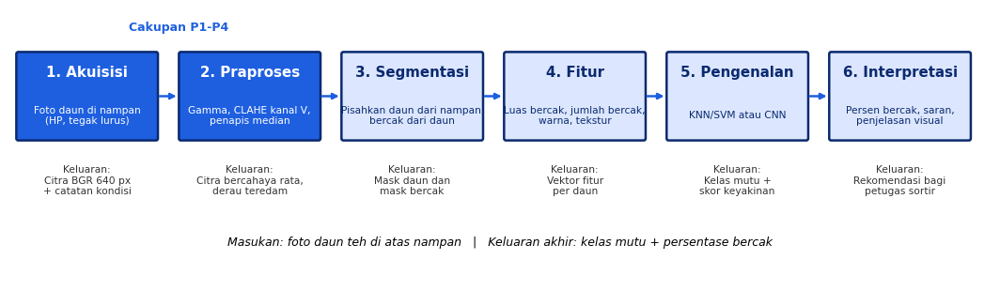

In [ ]:
from matplotlib.patches import FancyBboxPatch
tahap = [
  ("1. Akuisisi", "Foto daun di nampan\n(HP, tegak lurus)", "Citra BGR 640 px\n+ catatan kondisi"),
  ("2. Praproses", "Gamma, CLAHE kanal V,\npenapis median", "Citra bercahaya rata,\nderau teredam"),
  ("3. Segmentasi", "Pisahkan daun dari nampan,\nbercak dari daun", "Mask daun dan\nmask bercak"),
  ("4. Fitur", "Luas bercak, jumlah bercak,\nwarna, tekstur", "Vektor fitur\nper daun"),
  ("5. Pengenalan", "KNN/SVM atau CNN", "Kelas mutu +\nskor keyakinan"),
  ("6. Interpretasi", "Persen bercak, saran,\npenjelasan visual", "Rekomendasi bagi\npetugas sortir"),
]
fig, ax = plt.subplots(figsize=(15, 4.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 4.2); ax.axis("off")
for i, (nm, proses, keluar) in enumerate(tahap):
    x = 0.15 + i * 2.48
    ax.add_patch(FancyBboxPatch((x, 2.2), 2.1, 1.3, boxstyle="round,pad=0.03",
                                fc="#1E5FE0" if i < 2 else "#DCE7FF", ec="#0B2A6F", lw=2))
    ax.text(x + 1.05, 3.15, nm, ha="center", fontsize=12, weight="bold",
            color="white" if i < 2 else "#0B2A6F")
    ax.text(x + 1.05, 2.55, proses, ha="center", va="center", fontsize=8.5,
            color="white" if i < 2 else "#0B2A6F")
    ax.text(x + 1.05, 1.55, "Keluaran:\n" + keluar, ha="center", va="center", fontsize=8.5, color="#333")
    if i < 5:
        ax.annotate("", xy=(x + 2.45, 2.85), xytext=(x + 2.12, 2.85),
                    arrowprops=dict(arrowstyle="-|>", color="#1E5FE0", lw=2))
ax.text(7.5, 0.55, "Masukan: foto daun teh di atas nampan   |   Keluaran akhir: kelas mutu + persentase bercak",
        ha="center", fontsize=10, style="italic")
ax.text(2.6, 3.85, "Cakupan P1-P4", ha="center", fontsize=10, color="#1E5FE0", weight="bold")
plt.savefig("../hasil/b1_pipeline.png", bbox_inches="tight", dpi=150); plt.show()

### Tabel Risiko Responsible Computer Vision

In [ ]:
risiko = pd.DataFrame([
 ["Privasi citra", "Foto memuat wajah petugas atau metadata EXIF berisi lokasi GPS kebun",
  "Foto hanya bidang nampan; hapus EXIF otomatis sebelum disimpan; izin pemilik kebun"],
 ["Bias dan keadilan", "Data latih didominasi satu varietas, satu kebun, atau cahaya normal sehingga daun dari kebun lain lebih sering salah dinilai",
  "Rencana akuisisi mewakili 5 kondisi cahaya dan beberapa kebun; evaluasi kinerja per kondisi dan per sumber"],
 ["Transparansi", "Petani tidak tahu dasar sistem menilai daun berbercak berat",
  "Tampilkan mask bercak dan persen bercak di samping kelas mutu; jelaskan keterbatasan"],
 ["Keamanan data", "Repository atau penyimpanan cloud terbuka untuk umum",
  "Repository privat; akses hanya anggota tim; foto mentah tidak diunggah"],
 ["Dampak sosial", "Daun sehat dinilai berbercak sehingga harga jual petani turun; keputusan sepenuhnya diserahkan ke mesin",
  "SIMUTEH hanya alat bantu; keputusan akhir di tangan petugas; ambang kelas dikonsultasikan dengan kelompok tani"],
 ["Keterlacakan", "Hasil tidak dapat diulang karena parameter praproses tidak dicatat",
  "SEED, versi pustaka (requirements.txt), dan param_praproses.json disimpan di repository"],
], columns=["Aspek", "Risiko pada SIMUTEH", "Mitigasi awal"])
risiko.to_csv("../hasil/b1_risiko_rcv.csv", index=False)
display(risiko)

,Aspek,Risiko pada SIMUTEH,Mitigasi awal
0,Privasi citra,Foto memuat wajah petugas atau metadata EXIF b...,Foto hanya bidang nampan; hapus EXIF otomatis ...
1,Bias dan keadilan,"Data latih didominasi satu varietas, satu kebu...",Rencana akuisisi mewakili 5 kondisi cahaya dan...
2,Transparansi,Petani tidak tahu dasar sistem menilai daun be...,Tampilkan mask bercak dan persen bercak di sam...
3,Keamanan data,Repository atau penyimpanan cloud terbuka untu...,Repository privat; akses hanya anggota tim; fo...
4,Dampak sosial,Daun sehat dinilai berbercak sehingga harga ju...,SIMUTEH hanya alat bantu; keputusan akhir di t...
5,Keterlacakan,Hasil tidak dapat diulang karena parameter pra...,"SEED, versi pustaka (requirements.txt), dan pa..."


### Jawaban Pertanyaan Analisis Bagian 1

**P1.1 Semantic gap.** Petugas sortir melihat "daun teh dengan beberapa bercak pucat kekuningan" dan langsung tahu daun itu bermutu rendah. Komputer hanya menerima larik `uint8` berukuran (480, 640, 3) berisi 921.600 angka 0 sampai 255 dalam urutan BGR. Contohnya, piksel (y=100, x=200) bernilai [163 193 193], yaitu warna nampan, dan potongan 5 x 5 keabuan di dekat bercak berisi angka sekitar 87 sampai 129 yang tidak mengandung kata "bercak". Jarak antara angka-angka ini dan makna "daun berbercak berat" itulah semantic gap. SIMUTEH menjembataninya lewat tahap pipeline: praproses, segmentasi bercak, pengukuran luas, lalu klasifikasi.

**P1.2 Tiga sumber variasi yang paling mengganggu SIMUTEH.**
1. *Pencahayaan* (teduh, terik, bayangan atap). Ditangani pada tahap **akuisisi** (protokol pemotretan) dan **praproses** (gamma, CLAHE).
2. *Skala dan jarak* (petugas memotret dari jarak berbeda). Ditangani pada **akuisisi** (jarak tetap sekitar 20 cm, acuan ukuran berupa koin) dan pada **fitur** (memakai persentase luas bercak terhadap luas daun, bukan luas absolut).
3. *Derau dan latar* (derau sensor HP murah, nampan anyaman bertekstur). Ditangani pada **praproses** (penapis median) dan **segmentasi** (memisahkan daun dari nampan).
Oklusi (daun bertumpuk) juga mungkin terjadi dan ditangani pada tahap **pengenalan** dengan deteksi objek (P13).

**P1.3 BGR dan RGB.** OpenCV menyimpan kanal dalam urutan B, G, R, sedangkan Matplotlib menganggap R, G, B. Tanpa konversi, kanal merah dan biru tertukar: nampan krem tampak kebiruan dan bercak kuning tampak biru, sedangkan daun hijau hampir tidak berubah karena kanal G tetap di tengah. Bila kesalahan ini terbawa ke P9, fitur warna seperti "rerata kanal merah" sebenarnya dihitung dari kanal biru. Model akan belajar dari ciri yang salah, dan bila konversi saat pelatihan berbeda dengan saat pemakaian, prediksi menjadi kacau.

**P1.4 Dampak kesalahan.**
* *Daun sehat dinilai bercak berat (positif palsu):* yang dirugikan adalah petani, karena harga turun atau daun dibuang. Yang diuntungkan secara tidak adil adalah pembeli.
* *Daun berbercak berat dinilai sehat (negatif palsu):* yang dirugikan adalah pabrik atau pembeli, karena mutu teh turun. Kelompok tani juga dirugikan dalam jangka panjang: reputasinya turun dan penyakit dapat menyebar ke kebun lain.

Nilai **adil** menuntut kesalahan tidak lebih sering terjadi pada kelompok tertentu, misalnya kebun yang teduh atau difoto dengan HP murah. Karena itu evaluasi harus dilakukan per kondisi, bukan hanya rerata. Nilai **amanah** menuntut SIMUTEH disampaikan sebagai alat bantu beserta keterbatasannya, dengan keputusan akhir tetap di tangan petugas sortir.

## Bagian 2. Pembentukan Citra dan Ruang Warna
### Langkah 2.1 Lembar hitung (verifikasi dengan kode)

In [ ]:
f, piksel = 4.0, 0.0014          # mm
X, Z = 5.0, 300.0                # mm
W0, H0 = 4000, 3000

def bayangan_px(Z, X=5.0):
    x_mm = f * X / Z
    return x_mm, x_mm / piksel

xa, pa = bayangan_px(300); xb, pb = bayangan_px(600)
print(f"a) Z=300 mm: x = {xa:.4f} mm = {pa:.1f} piksel")
print(f"b) Z=600 mm: x = {xb:.4f} mm = {pb:.1f} piksel  (jarak 2x, ukuran 1/2)")
Zc = f * X / (10 * piksel)
print(f"c) Z maksimum agar bercak >= 10 piksel: {Zc:.0f} mm")
skala = 640 / W0
butuh_asli = 10 / skala
Zd = f * X / (butuh_asli * piksel)
print(f"d) setelah diperkecil ke lebar 640 (skala {skala}): {pa*skala:.1f} piksel;"
      f" agar tetap >= 10 piksel perlu {butuh_asli:.1f} piksel di foto asli -> Z maks {Zd:.0f} mm")
mem = lambda w, h, c, b=8: w * h * c * b / 8
print(f"e) foto asli {mem(W0,H0,3):,.0f} B | 640x480 warna {mem(640,480,3):,.0f} B |"
      f" 640x480 abu {mem(640,480,1):,.0f} B | 300 foto asli {300*mem(W0,H0,3)/1e9:.1f} GB")
for nm, rgb in {"bercak": (196, 178, 86), "daun": (52, 136, 60)}.items():
    R, G, B = rgb
    Y = 0.299 * R + 0.587 * G + 0.114 * B
    px = np.uint8([[[B, G, R]]])
    print(f"f) {nm}: Y manual = {Y:.2f} | cv2 gray = {cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0,0]}"
          f" | Hue OpenCV = {cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0,0,0]}")

a) Z=300 mm: x = 0.0667 mm = 47.6 piksel
b) Z=600 mm: x = 0.0333 mm = 23.8 piksel  (jarak 2x, ukuran 1/2)
c) Z maksimum agar bercak >= 10 piksel: 1429 mm
d) setelah diperkecil ke lebar 640 (skala 0.16): 7.6 piksel; agar tetap >= 10 piksel perlu 62.5 piksel di foto asli -> Z maks 229 mm
e) foto asli 36,000,000 B | 640x480 warna 921,600 B | 640x480 abu 307,200 B | 300 foto asli 10.8 GB
f) bercak: Y manual = 172.89 | cv2 gray = 173 | Hue OpenCV = 25
f) daun: Y manual = 102.22 | cv2 gray = 102 | Hue OpenCV = 63


### Jawaban Lembar Hitung Bagian 2

| Butir | Penyelesaian | Jawaban |
|---|---|---|
| a | x = 4,0 x 5 / 300 = 0,0667 mm; 0,0667 / 0,0014 | **47,6 piksel** |
| b | x = 4,0 x 5 / 600 = 0,0333 mm | **23,8 piksel**; jarak 2 kali lipat, ukuran menjadi setengah (berbanding terbalik dengan Z) |
| c | 10 piksel = 0,014 mm; Z = f X / x = 20 / 0,014 | **Z maks sekitar 1.429 mm** |
| d | skala 640/4000 = 0,16; 47,6 x 0,16. Agar 10 piksel setelah diperkecil, perlu 62,5 piksel di foto asli: x = 0,0875 mm; Z = 20 / 0,0875 | **7,6 piksel** (kurang dari 10); **Z maks sekitar 229 mm** |
| e | 4000 x 3000 x 3; 640 x 480 x 3; 640 x 480 x 1; 300 x 36 MB | **36.000.000 B; 921.600 B; 307.200 B; 10,8 GB** |
| f | Y = 0,299R + 0,587G + 0,114B | **Bercak 172,89 (173); daun 102,22 (102); selisih sekitar 71.** Hue OpenCV: bercak 25 (50 derajat, kuning), daun 63 (126 derajat, hijau) |

### Langkah 2.2 Rencana akuisisi citra

In [ ]:
rencana = pd.DataFrame([
 ["Jarak dan sudut", "Tegak lurus dari atas, jarak sekitar 20 cm (satu jengkal); maksimal 23 cm agar bercak 5 mm tetap >= 10 piksel setelah diperkecil ke lebar 640 px"],
 ["Resolusi minimum", "Foto asli minimal 12 MP (4000 x 3000); bila jarak lebih jauh, lebar kerja dinaikkan (misalnya 1280 px)"],
 ["Alas dan acuan ukuran", "Nampan atau kertas HVS polos berwarna terang; koin Rp500 atau penggaris di sudut bingkai untuk konversi piksel ke mm (P6)"],
 ["Kondisi cahaya", "Mewakili 5 kondisi: normal, teduh/gelap, terik, berkabut/kontras rendah, bayangan sebagian; catat kondisi setiap foto"],
 ["Jumlah citra", "Minimal 100 citra per kelas (Sehat, Ringan, Berat), seimbang antarkelas dan antarkondisi, dari minimal 3 kebun"],
 ["Penamaan berkas", "<kebun>_<kondisi>_<kelas>_<nomor>.jpg, misalnya k01_teduh_ringan_007.jpg; dicatat di catatan_akuisisi.csv"],
 ["Izin dan privasi", "Izin tertulis ketua kelompok tani; EXIF dihapus otomatis; tidak ada wajah/tangan beridentitas; foto mentah tidak diunggah ke repository publik"],
], columns=["Aspek", "Ketentuan"])
rencana.to_csv("../hasil/b2_rencana_akuisisi.csv", index=False)
display(rencana)

,Aspek,Ketentuan
0,Jarak dan sudut,"Tegak lurus dari atas, jarak sekitar 20 cm (sa..."
1,Resolusi minimum,Foto asli minimal 12 MP (4000 x 3000); bila ja...
2,Alas dan acuan ukuran,Nampan atau kertas HVS polos berwarna terang; ...
3,Kondisi cahaya,"Mewakili 5 kondisi: normal, teduh/gelap, terik..."
4,Jumlah citra,"Minimal 100 citra per kelas (Sehat, Ringan, Be..."
5,Penamaan berkas,"<kebun>_<kondisi>_<kelas>_<nomor>.jpg, misalny..."
6,Izin dan privasi,Izin tertulis ketua kelompok tani; EXIF dihapu...


### Kode 2.1 Pemisahan kanal dan Kontras Bercak

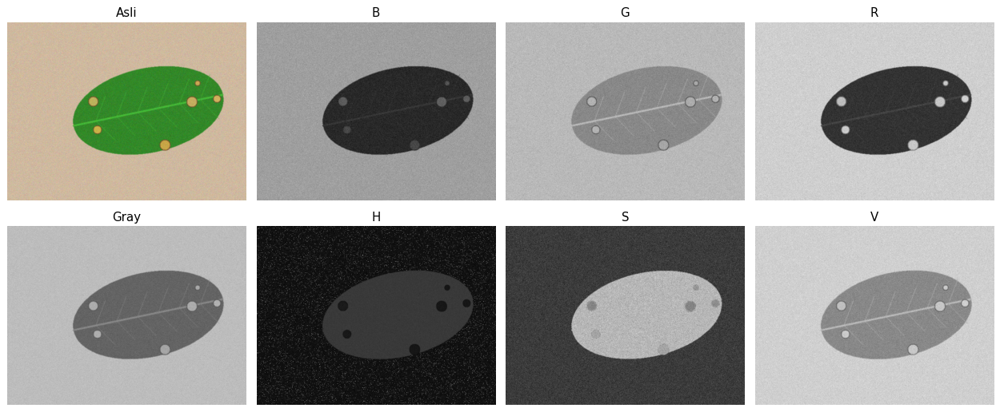

KB kanal B   : 2.87
KB kanal G   : 0.92
KB kanal R   : 10.67
KB kanal Gray: 5.19
KB kanal H   : 8.00
KB kanal S   : 1.81
KB kanal V   : 2.84


In [ ]:
nama = "teh_041.png"                 # kelas berat, kondisi normal
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", bbox_inches="tight"); plt.show()
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

### Kode 2.2 Sampling dan kuantisasi

,fx,ukuran,KB
0,0.50,320x240,6.32
1,0.20,128x96,5.49
2,0.10,64x48,3.95
3,0.05,32x24,2.10


,bit,jumlah level,KB
0,1,2,4.71
1,2,3,4.73
2,3,5,2.98
3,4,10,4.60
4,8,149,5.19


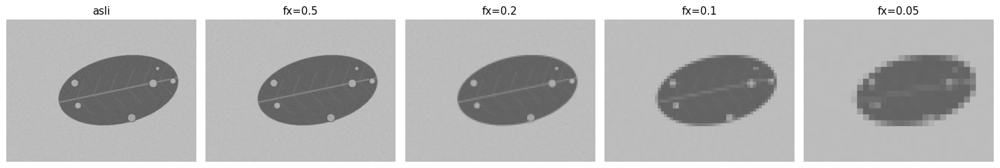

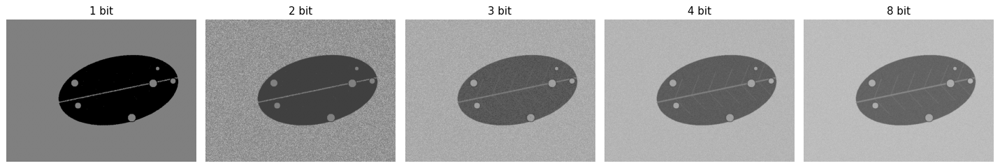

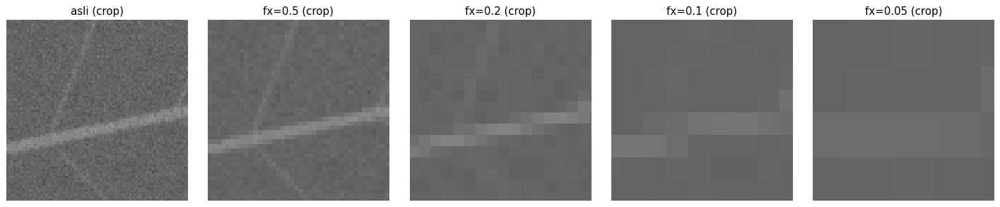

In [ ]:
hasil_s, gbr_s = [], []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    hasil_s.append([fx, f"{kecil.shape[1]}x{kecil.shape[0]}", round(kontras_bercak(besar, md, mb), 2)])
    gbr_s.append(besar)
hasil_k, gbr_k = [], []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hasil_k.append([k, len(np.unique(kuant)), round(kontras_bercak(kuant, md, mb), 2)])
    gbr_k.append(kuant)
display(pd.DataFrame(hasil_s, columns=["fx", "ukuran", "KB"]))
display(pd.DataFrame(hasil_k, columns=["bit", "jumlah level", "KB"]))
tampil([gray] + gbr_s, ["asli"] + [f"fx={x[0]}" for x in hasil_s], ukuran=(16, 3.2))
plt.savefig("../hasil/b2_sampling.png", bbox_inches="tight"); plt.show()
tampil(gbr_k, [f"{x[0]} bit" for x in hasil_k], ukuran=(16, 3.2))
plt.savefig("../hasil/b2_kuantisasi.png", bbox_inches="tight"); plt.show()

# perbesar daerah bercak terbesar agar efek sampling terlihat
ys, xs = np.where(mb > 0); cy, cx = int(np.median(ys)), int(np.median(xs))
pot = lambda im: im[max(cy-40,0):cy+40, max(cx-40,0):cx+40]
tampil([pot(gray)] + [pot(x) for x in gbr_s], ["asli (crop)"] + [f"fx={x[0]} (crop)" for x in hasil_s], ukuran=(16, 3.2))
plt.show()

### Kode 2.3 Rerata KB per kanal dan per kondisi (kelas berat dan kelas ringan)

Kelas BERAT


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.47,0.35,5.32,1.64,4.77,1.14,0.90
gelap,1.03,1.60,9.94,4.65,5.36,0.60,3.31
kontras_rendah,0.74,0.47,3.36,1.99,1.35,0.30,1.38
normal,2.39,1.48,10.02,5.25,7.03,1.27,3.30
terang,1.94,0.59,6.78,3.58,5.24,1.05,1.65
RERATA,1.51,0.90,7.08,3.42,4.75,0.87,2.11


Kelas RINGAN


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,0.60,0.81,4.28,1.22,4.71,0.71,0.92
gelap,0.83,0.85,6.51,1.39,5.82,1.24,0.55
kontras_rendah,0.44,0.54,2.44,0.73,0.98,0.35,0.44
normal,1.06,0.81,8.18,2.33,8.30,0.76,0.81
terang,0.66,0.56,6.05,2.15,5.73,0.84,0.98
RERATA,0.72,0.71,5.49,1.56,5.11,0.78,0.74


Kanal dengan rerata KB tertinggi (kelas berat): R


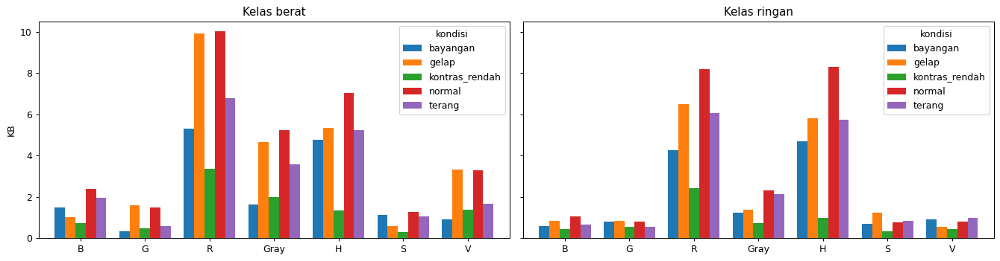

In [ ]:
def semua_kanal(im):
    hsv_ = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    b_, g_, r_ = cv2.split(im); h_, s_, v_ = cv2.split(hsv_)
    return {"B": b_, "G": g_, "R": r_, "Gray": cv2.cvtColor(im, cv2.COLOR_BGR2GRAY),
            "H": h_, "S": s_, "V": v_}

def tabel_kb_kelas(kelas):
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im, m_d, m_b = muat(d.nama_file)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    t = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
    t.loc["RERATA"] = t.mean().round(2)
    return t

tabel_kb = tabel_kb_kelas("berat");  tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")
tabel_kb_r = tabel_kb_kelas("ringan"); tabel_kb_r.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("Kelas BERAT"); display(tabel_kb)
print("Kelas RINGAN"); display(tabel_kb_r)
KANAL_TERBAIK = tabel_kb.loc["RERATA"].idxmax()
print("Kanal dengan rerata KB tertinggi (kelas berat):", KANAL_TERBAIK)

fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a, (jd, t) in zip(ax, [("Kelas berat", tabel_kb), ("Kelas ringan", tabel_kb_r)]):
    t.drop("RERATA").T.plot.bar(ax=a, rot=0, width=0.8); a.set_title(jd); a.set_ylabel("KB")
plt.tight_layout(); plt.savefig("../hasil/b2_grafik_kb.png", bbox_inches="tight"); plt.show()

### Langkah 2.6 Kanal terbaik pada teh_021 (ringan, normal) dan teh_045 (berat, bayangan)

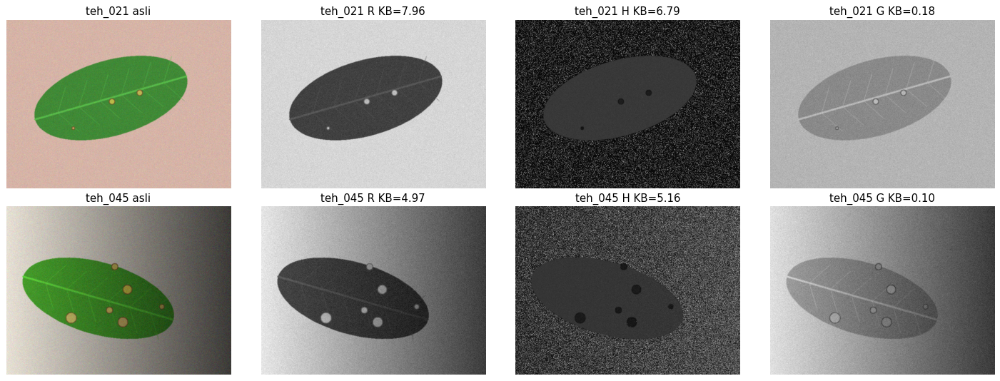

In [ ]:
daftar, judul = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im, m_d, m_b = muat(nm)
    kn = semua_kanal(im)
    daftar.append(im); judul.append(f"{nm[:7]} asli")
    for k in ["R", "H", "G"]:
        daftar.append(kn[k]); judul.append(f"{nm[:7]} {k} KB={kontras_bercak(kn[k], m_d, m_b):.2f}")
tampil(daftar, judul, baris=2, ukuran=(16, 6))
plt.savefig("../hasil/b2_panel_ringan_bayangan.png", bbox_inches="tight"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 2

**P2.1 Aturan pemotretan.** Dari butir d), bila citra kerja diperkecil ke lebar 640 piksel, bercak 5 mm hanya tetap selebar 10 piksel atau lebih bila dipotret dari jarak paling jauh sekitar 23 cm. Aturan untuk petugas: **"Potret daun tegak lurus dari atas, sejauh satu jengkal (sekitar 20 cm), dengan kamera minimal 12 MP, dan pastikan daun memenuhi sebagian besar layar."** Bila jarak 30 cm lebih nyaman, lebar kerja harus dinaikkan menjadi 1280 piksel, sehingga jarak maksimumnya menjadi sekitar 46 cm, dengan konsekuensi biaya komputasi 4 kali lipat.

**P2.2 Kanal terbaik.** Kanal **R** memberi KB tertinggi secara konsisten di semua kondisi. Untuk kelas berat, KB-nya 3,65 sampai 10,06 (rerata 7,15); untuk kelas ringan, 4,10 sampai 10,72 (rerata 6,71). Peringkat kedua adalah H, sedangkan G dan S terendah. Secara fisik, bercak cacar daun berwarna pucat kekuningan (R sekitar 196) sedangkan daun hijau memiliki komponen merah rendah (R sekitar 52), sehingga selisih di kanal R sangat besar. Di kanal G keduanya sama-sama tinggi (178 dan 136), sehingga bercak sulit dibedakan. Keabuan mencampur ketiga kanal dan mengencerkan perbedaan R, sedangkan S rendah karena bercak kuning dan daun hijau sama-sama berwarna pekat.

**P2.3 Apakah H tahan perubahan cahaya?** Sebagian besar ya. Pada kelas berat, KB H pada kondisi bayangan (5,56), gelap (5,78), dan terang (6,03) hampir sama dengan kondisi normal (6,43), sedangkan KB V anjlok menjadi 1,07, 3,19, dan 1,84. Jadi H memang memisahkan warna dari kecerahan. Namun H tidak kebal: pada kondisi kontras rendah KB H turun menjadi 1,82, karena warna menjadi pudar (saturasi rendah) dan nilai Hue menjadi tidak stabil serta peka derau. Pada data ini R tetap lebih unggul daripada H.

**P2.4 Keterbatasan KB pada kuantisasi.** Pada 1 bit KB = 5,64 dan pada 2 bit KB = 5,77, lebih tinggi daripada 8 bit (5,05). Secara visual, citra 1 bit kehilangan seluruh detail: daun menjadi hitam rata, dan tulang daun serta gradasi lenyap. KB naik bukan karena citranya lebih baik, melainkan karena kuantisasi menyeragamkan nilai daun sehingga simpangan bakunya (pembagi KB) mengecil. Hasilnya juga tidak monoton (3 bit hanya 2,99), karena bercak dan daun bisa jatuh ke tingkat yang sama atau berbeda tergantung letak batas kuantisasi. Artinya KB hanya mengukur keterpisahan bercak dari daun, bukan mutu citra secara umum, dan harus didampingi pengamatan visual serta ukuran lain.

**P2.5 Faktor sampling.** Pada fx = 0,5, KB justru naik (6,54) karena `INTER_AREA` merata-ratakan piksel dan meredam derau. Pada fx = 0,2, KB masih 5,48 dan bercak masih terlihat. Pada **fx = 0,1** (64 x 48), bercak kecil hanya tersisa 1 sampai 2 blok piksel dan mulai sulit dibedakan (KB 3,65). Pada fx = 0,05, bercak kecil hilang (KB 1,97). Diameter bercak sintetis sekitar 10 sampai 30 piksel, sehingga pada fx = 0,1 tinggal 1 sampai 3 piksel, jauh di bawah syarat 10 piksel dari butir 2.1 d).

**P2.6 Risiko EXIF.** EXIF dapat memuat koordinat GPS kebun, tanggal dan jam pemotretan, serta merek HP. Bila foto diunggah ke repository publik, lokasi kebun petani beserta data "kebun ini terserang cacar daun" dapat diketahui siapa saja. Akibatnya petani bisa dirugikan: harga ditekan pembeli, kebun distigma, atau keamanan kebun terancam. Rencana akuisisi mencegahnya dengan menghapus EXIF otomatis, menyimpan foto mentah di luar repository, memakai repository privat, dan meminta izin tertulis kelompok tani.

## Bagian 3. Histogram dan Perbaikan Citra
### Langkah 3.1 Lembar hitung (verifikasi dengan kode)

a) histogram: {1: 2, 2: 7, 3: 6, 4: 1}
b) peregangan:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]


,r,n,PDF,CDF,7xCDF,s
0,1,2,0.1250,0.1250,0.8750,1
1,2,7,0.4375,0.5625,3.9375,4
2,3,6,0.3750,0.9375,6.5625,7
3,4,1,0.0625,1.0000,7.0000,7


c) hasil ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
d) negatif r=60 -> 195 | kontras r=120 -> 138.0 | kontras r=210 -> 255 | gamma 0.6 r=100 -> 145.42 | gamma 1.8 r=100 -> 47.29


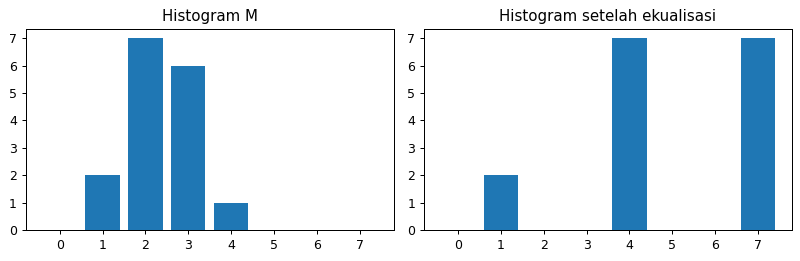

In [ ]:
M = np.array([[1, 2, 2, 3], [2, 2, 3, 3], [1, 2, 3, 4], [2, 3, 3, 2]])
L = 8
nilai, n = np.unique(M, return_counts=True)
print("a) histogram:", dict(zip(nilai.tolist(), n.tolist())))
regang = np.floor((M - M.min()) / (M.max() - M.min()) * (L - 1) + 0.5).astype(int)
print("b) peregangan:\n", regang)
pdf = n / M.size; cdf = np.cumsum(pdf)
s_eq = np.floor((L - 1) * cdf + 0.5).astype(int)
tab = pd.DataFrame({"r": nilai, "n": n, "PDF": pdf, "CDF": cdf, "7xCDF": (L - 1) * cdf, "s": s_eq})
display(tab)
peta = dict(zip(nilai, s_eq))
print("c) hasil ekualisasi:\n", np.vectorize(peta.get)(M))
gam = lambda r, g: 255 * (r / 255) ** g
print("d) negatif r=60 ->", 255 - 60,
      "| kontras r=120 ->", 1.4 * 120 - 30, "| kontras r=210 ->", min(1.4 * 210 - 30, 255),
      "| gamma 0.6 r=100 ->", round(gam(100, 0.6), 2), "| gamma 1.8 r=100 ->", round(gam(100, 1.8), 2))
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.bar(range(8), np.bincount(M.ravel(), minlength=8)); plt.title("Histogram M")
plt.subplot(1, 2, 2); plt.bar(range(8), np.bincount(np.vectorize(peta.get)(M).ravel(), minlength=8))
plt.title("Histogram setelah ekualisasi"); plt.tight_layout(); plt.show()

### Jawaban Lembar Hitung Bagian 3

* **a) Histogram M:** h(1) = 2, h(2) = 7, h(3) = 6, h(4) = 1, total 16 piksel.
* **b) Peregangan** s = (r - 1)/3 x 7: 1 menjadi 0, 2 menjadi 2,33 (2), 3 menjadi 4,67 (5), 4 menjadi 7. Hasilnya [[0,2,2,5],[2,2,5,5],[0,2,5,7],[2,5,5,2]].
* **c) Ekualisasi:** lihat tabel keluaran (s = 1, 4, 7, 7). Hasilnya [[1,4,4,7],[4,4,7,7],[1,4,7,7],[4,7,7,4]].
* **d) Operasi titik:** negatif r = 60 menjadi **195**; kontras r = 120 menjadi **138**; r = 210 menjadi 264, dipotong **255**; gamma 0,6 pada r = 100 menjadi **145**; gamma 1,8 pada r = 100 menjadi **47**.

### Kode 3.1 Statistik dan histogram untuk diagnosis

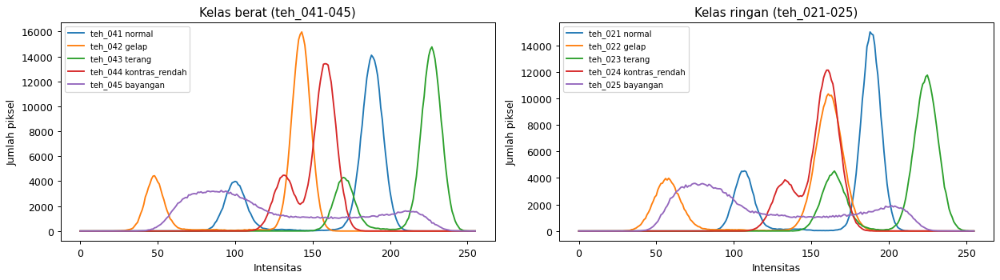

,Citra,Kondisi,Rerata,Simp. baku,Min-maks,% gelap,% terang,Diagnosis,Usulan perbaikan
0,teh_041.png,normal,168.3,37.4,69-218,0.0,0.4,baik,tidak perlu perbaikan berat
1,teh_042.png,gelap,121.9,39.2,17-169,12.7,0.0,terlalu gelap,"gamma < 1 (mis. 0,6)"
2,teh_043.png,terang,213.4,24.6,135-250,0.0,75.9,terlalu terang,"gamma > 1 (mis. 1,6)"
3,teh_044.png,kontras_rendah,151.6,13.4,103-189,0.0,0.0,kontras rendah,peregangan kontras / CLAHE
4,teh_045.png,bayangan,125.8,51.1,31-248,0.4,10.9,cahaya tidak merata,"CLAHE (clip 1, tile 4)"
5,teh_021.png,normal,168.8,35.4,78-218,0.0,0.2,baik,tidak perlu perbaikan berat
6,teh_022.png,gelap,132.3,47.4,10-202,5.1,0.0,baik,tidak perlu perbaikan berat
7,teh_023.png,terang,207.5,27.7,133-252,0.0,71.1,terlalu terang,"gamma > 1 (mis. 1,6)"
8,teh_024.png,kontras_rendah,153.9,14.0,98-196,0.0,0.0,kontras rendah,peregangan kontras / CLAHE
9,teh_025.png,bayangan,120.9,50.5,34-238,0.5,6.7,cahaya tidak merata,"CLAHE (clip 1, tile 4)"


In [ ]:
def diagnosis(st):
    if st["simpangan_baku"] < 20:                 return "kontras rendah", "peregangan kontras / CLAHE"
    if st["persen_terang"] > 40:                  return "terlalu terang", "gamma > 1 (mis. 1,6)"
    if st["persen_gelap"] > 10 or st["maks"] < 170: return "terlalu gelap", "gamma < 1 (mis. 0,6)"
    if st["simpangan_baku"] > 50:                 return "cahaya tidak merata", "CLAHE (clip 1, tile 4)"
    return "baik", "tidak perlu perbaikan berat"

baris = []
plt.figure(figsize=(14, 4))
for i, nama in enumerate(["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
                         + [f"teh_0{k}.png" for k in range(21, 26)]):
    gr = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    st = statistik(gr); dg, us = diagnosis(st)
    kond = label.set_index("nama_file").loc[nama, "kondisi_cahaya"]
    baris.append([nama, kond, st["rerata"], st["simpangan_baku"], f'{st["min"]}-{st["maks"]}',
                  st["persen_gelap"], st["persen_terang"], dg, us])
    plt.subplot(1, 2, 1 if i < 5 else 2)
    plt.plot(cv2.calcHist([gr], [0], None, [256], [0, 256]), label=f"{nama[:7]} {kond}")
for k, jd in [(1, "Kelas berat (teh_041-045)"), (2, "Kelas ringan (teh_021-025)")]:
    plt.subplot(1, 2, k); plt.title(jd); plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../hasil/b3_histogram_5kondisi.png", bbox_inches="tight"); plt.show()
diag = pd.DataFrame(baris, columns=["Citra", "Kondisi", "Rerata", "Simp. baku", "Min-maks",
                                    "% gelap", "% terang", "Diagnosis", "Usulan perbaikan"])
diag.to_csv("../hasil/b3_diagnosis.csv", index=False); display(diag)

### Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE (citra bayangan teh_045)

,Metode,Parameter,KB,Simpangan baku,Pengamatan visual
0,asli,-,1.29,51.1,"sisi kanan teduh, bercak di sisi teduh samar"
1,negatif,s = 255 - r,1.29,51.1,hanya membalik; KB tetap
2,cerah+50,b = 50,1.29,48.7,semua naik; area terang terpotong di 255
3,kontras,"a = 1,5; b = -40",1.29,70.5,kontras global naik; sisi terang jenuh
4,regang,persentil 2-98,1.32,77.4,rentang penuh dipakai; sisi teduh tetap gelap
5,gamma0.5,"gamma = 0,5",1.15,35.8,sisi teduh lebih cerah tetapi daun ikut pucat
6,gamma1.8,"gamma = 1,8",1.53,56.8,daun lebih gelap sehingga bercak terang lebih ...
7,ekualisasi,global,1.01,73.4,beda sisi terang-teduh justru diperkuat
8,CLAHE,clip 2; tile 8,1.68,44.5,kecerahan lokal lebih rata; bercak sisi teduh ...


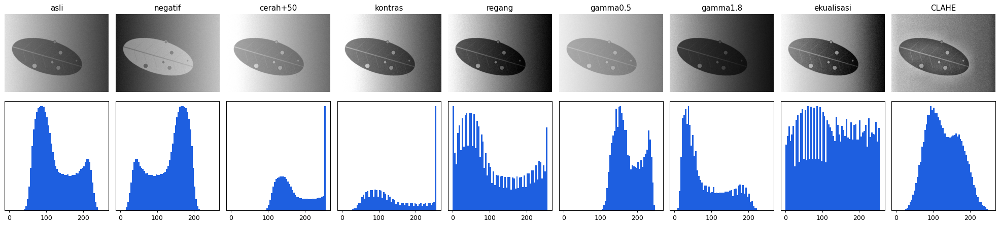

In [ ]:
nama = "teh_045.png"
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": (gray, "-"),
    "negatif": (255 - gray, "s = 255 - r"),
    "cerah+50": (cv2.add(gray, 50), "b = 50"),
    "kontras": (cv2.convertScaleAbs(gray, alpha=1.5, beta=-40), "a = 1,5; b = -40"),
    "regang": (np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8), "persentil 2-98"),
    "gamma0.5": (cv2.LUT(gray, gamma_lut(0.5)), "gamma = 0,5"),
    "gamma1.8": (cv2.LUT(gray, gamma_lut(1.8)), "gamma = 1,8"),
    "ekualisasi": (cv2.equalizeHist(gray), "global"),
    "CLAHE": (cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray), "clip 2; tile 8"),
}
catatan = {"asli": "sisi kanan teduh, bercak di sisi teduh samar",
           "negatif": "hanya membalik; KB tetap",
           "cerah+50": "semua naik; area terang terpotong di 255",
           "kontras": "kontras global naik; sisi terang jenuh",
           "regang": "rentang penuh dipakai; sisi teduh tetap gelap",
           "gamma0.5": "sisi teduh lebih cerah tetapi daun ikut pucat",
           "gamma1.8": "daun lebih gelap sehingga bercak terang lebih menonjol",
           "ekualisasi": "beda sisi terang-teduh justru diperkuat",
           "CLAHE": "kecerahan lokal lebih rata; bercak sisi teduh lebih jelas"}
baris = [[nm, par, round(kontras_bercak(c, md, mb), 2), round(c.std(), 1), catatan[nm]]
         for nm, (c, par) in hasil.items()]
tab_b3 = pd.DataFrame(baris, columns=["Metode", "Parameter", "KB", "Simpangan baku", "Pengamatan visual"])
tab_b3.to_csv("../hasil/b3_perbaikan.csv", index=False); display(tab_b3)

fig, ax = plt.subplots(2, 9, figsize=(22, 5.2))
for i, (nm, (c, _)) in enumerate(hasil.items()):
    ax[0, i].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(nm); ax[0, i].axis("off")
    ax[1, i].hist(c.ravel(), bins=64, range=(0, 256), color="#1E5FE0"); ax[1, i].set_yticks([])
plt.tight_layout(); plt.savefig("../hasil/b3_histogram.png", bbox_inches="tight"); plt.show()

### Kode 3.3 Eksperimen CLAHE dan CLAHE pada citra warna

tile,4,8,16
clipLimit,,,
1.0,2.18,1.73,1.77
2.0,2.22,1.68,1.65
4.0,1.90,1.49,1.39


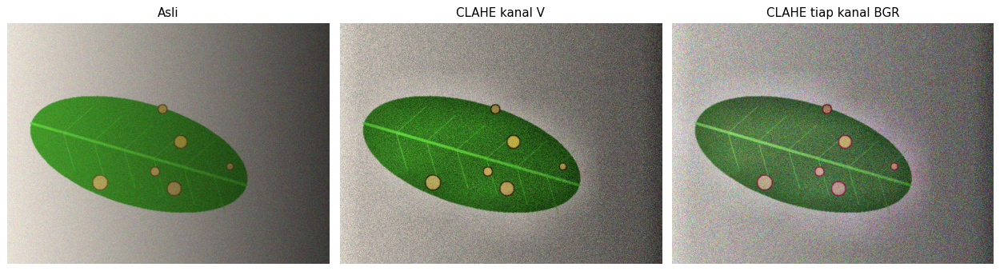

,Hue daun,Hue bercak,Saturasi daun
Asli,53.3,25.1,185.3
CLAHE kanal V,53.3,25.1,186.6
CLAHE tiap kanal,59.2,73.6,136.4


In [ ]:
baris = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        baris.append([clip, tile, round(kontras_bercak(c, md, mb), 2)])
tab_clahe = pd.DataFrame(baris, columns=["clipLimit", "tile", "KB"]).pivot(index="clipLimit", columns="tile", values="KB")
display(tab_clahe)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", bbox_inches="tight"); plt.show()

# bukti: pergeseran Hue di area daun dan area bercak
def hue_rerata(im, mask):
    hh = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float)
    return hh[mask].mean()
daun = (md > 0) & (mb == 0); brc = mb > 0
bukti = pd.DataFrame({
    "Hue daun": [hue_rerata(x, daun) for x in (img, via_v, via_bgr)],
    "Hue bercak": [hue_rerata(x, brc) for x in (img, via_v, via_bgr)],
    "Saturasi daun": [cv2.cvtColor(x, cv2.COLOR_BGR2HSV)[:, :, 1][daun].mean() for x in (img, via_v, via_bgr)],
}, index=["Asli", "CLAHE kanal V", "CLAHE tiap kanal"]).round(1)
display(bukti)

### Langkah 3.5 Perbaikan per kondisi untuk kelas berat dan kelas ringan

,Kondisi,Citra,Kelas,Perbaikan,KB sebelum,KB sesudah
0,gelap,teh_042.png,berat,"gamma 0,6",4.35,3.73
1,gelap,teh_022.png,ringan,"gamma 0,6",2.12,1.73
2,terang,teh_043.png,berat,"gamma 1,6",3.48,3.70
3,terang,teh_023.png,ringan,"gamma 1,6",1.57,1.67
4,kontras_rendah,teh_044.png,berat,peregangan 2-98,2.13,2.27
5,kontras_rendah,teh_024.png,ringan,peregangan 2-98,0.91,1.02
6,bayangan,teh_045.png,berat,CLAHE clip 1 tile 4,1.29,2.18
7,bayangan,teh_025.png,ringan,CLAHE clip 1 tile 4,0.60,1.40


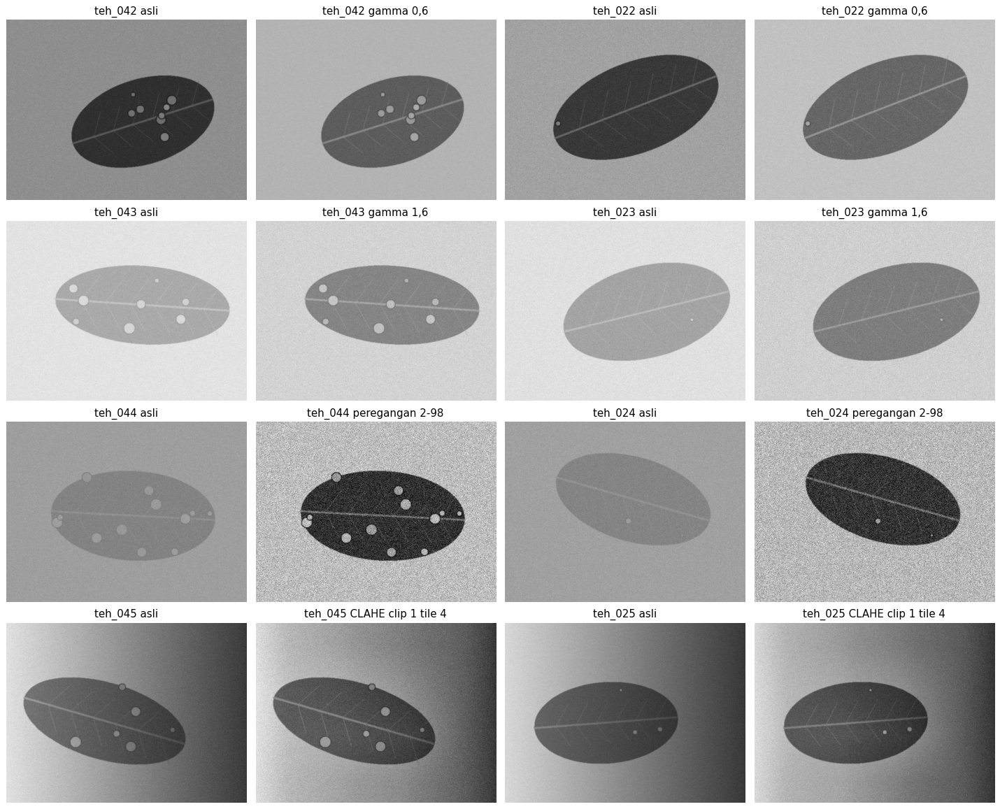

In [ ]:
clahe_lokal = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(4, 4))
def regang_p(x):
    lo, hi = np.percentile(x, (2, 98))
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
pilihan = {
    "gelap":          ("gamma 0,6", lambda x: cv2.LUT(x, gamma_lut(0.6)), ["teh_042.png", "teh_022.png"]),
    "terang":         ("gamma 1,6", lambda x: cv2.LUT(x, gamma_lut(1.6)), ["teh_043.png", "teh_023.png"]),
    "kontras_rendah": ("peregangan 2-98", regang_p,                     ["teh_044.png", "teh_024.png"]),
    "bayangan":       ("CLAHE clip 1 tile 4", clahe_lokal.apply,        ["teh_045.png", "teh_025.png"]),
}
baris, daftar, judul = [], [], []
for kond, (nm_m, fn, citra) in pilihan.items():
    for nama in citra:
        im, m_d, m_b = muat(nama)
        gr = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY); out = fn(gr)
        kelas = label.set_index("nama_file").loc[nama, "kelas"]
        baris.append([kond, nama, kelas, nm_m, round(kontras_bercak(gr, m_d, m_b), 2), round(kontras_bercak(out, m_d, m_b), 2)])
        daftar += [gr, out]; judul += [f"{nama[:7]} asli", f"{nama[:7]} {nm_m}"]
tab_35 = pd.DataFrame(baris, columns=["Kondisi", "Citra", "Kelas", "Perbaikan", "KB sebelum", "KB sesudah"])
display(tab_35)
tampil(daftar, judul, baris=4, ukuran=(16, 13))
plt.savefig("../hasil/b3_perbaikan_per_kondisi.png", bbox_inches="tight"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 3

**P3.1** Nilai 3 dan 4 sama-sama menjadi 7 karena CDF level 3 sudah 0,9375 sehingga 7 x 0,9375 dibulatkan menjadi 7. Perbedaan antara kedua level itu **hilang permanen** dan tidak dapat dikembalikan. Ekualisasi hanya memindahkan letak level berdasarkan CDF; ia tidak menciptakan level baru, dapat menggabungkan level yang jarang muncul (level 4 hanya 1 piksel), dan tidak menjamin seluruh rentang terpakai (level terendah menjadi 1, bukan 0). Jadi ekualisasi tidak menambah informasi, hanya menata ulang tampilan.

**P3.2** Histogram citra bayangan (teh_045) melebar dan cenderung dua kelompok, yaitu sisi terang dan sisi teduh (simpangan baku 54, rentang 28 sampai 236). Ekualisasi global memakai satu CDF untuk seluruh citra, sehingga perbedaan populasi terbesar, yaitu sisi terang lawan sisi teduh, yang paling diperkuat, bukan perbedaan bercak lawan daun. Hasilnya KB turun dari 2,86 menjadi **1,86**. CLAHE menghitung ekualisasi per blok dengan batas penguatan, sehingga kontras lokal di sisi teduh ikut diperbaiki: KB naik menjadi 3,09 (clip 2, tile 8) dan **3,55 (clip 1, tile 4)**. Ini sama dengan kasus kebun teh pada slide P3: separuh daun terkena matahari dan separuh dalam bayangan, sehingga metode lokal lebih tepat.

**P3.3** Peregangan min-maks gagal bila ada sedikit piksel ekstrem. Contohnya, daun bernilai 100 sampai 160, tetapi ada satu piksel mati bernilai 0 dan satu pantulan cahaya bernilai 255. Maka r_min = 0 dan r_maks = 255, sehingga s = r dan tidak ada peregangan sama sekali. Dengan persentil 2 dan 98, r_min sekitar 100 dan r_maks sekitar 160, sehingga 100 menjadi 0, 130 menjadi 128, dan 160 menjadi 255. Kontras daun benar-benar meningkat.

**P3.4** Bukti dari Kode 3.3: CLAHE pada kanal V tidak mengubah Hue (daun tetap 53,3 dan bercak tetap 23,9). CLAHE pada tiap kanal B, G, R mengubah Hue bercak dari **23,9 (kuning) menjadi 57,3 (hijau)** dan menurunkan saturasi daun dari 185 menjadi 137. Ekualisasi per kanal mengubah rasio antarkanal sehingga warna bergeser. Akibatnya bercak tampak hijau seperti daun sehat, yang fatal bagi SIMUTEH. Kanal V hanya membawa kecerahan, sehingga warna aman.

**P3.5** Satu pengaturan tidak cukup. Hasil Langkah 3.5 menunjukkan:
* gamma 1,6 membantu kondisi terang (KB 4,09 menjadi 4,37 pada berat; 2,56 menjadi 2,73 pada ringan);
* gamma 0,6 mencerahkan citra gelap secara visual, tetapi KB keabuan turun (5,78 menjadi 4,75) karena keragaman daun ikut melebar;
* peregangan hanya sedikit membantu kontras rendah (1,84 menjadi 1,97);
* CLAHE membantu bayangan kelas berat (2,86 menjadi 3,55), tetapi sedikit menurunkan kelas ringan (2,90 menjadi 2,74).

Aturan sederhana berbasis statistik histogram, yang dipakai pada fungsi `diagnosis()` dan diterapkan otomatis di Bagian 5:
* simpangan baku < 20 berarti **kontras rendah**, tangani dengan peregangan;
* persen terang > 40 berarti **terlalu terang**, tangani dengan gamma 1,6;
* persen gelap > 10 atau maksimum < 170 berarti **terlalu gelap**, tangani dengan gamma 0,6;
* simpangan baku > 50 berarti **cahaya tidak merata**, tangani dengan CLAHE (clip 1, tile 4);
* selain itu tanpa perbaikan.

Aturan ini mendiagnosis kesepuluh citra uji dengan benar.

**P3.6** Contoh perbaikan berlebihan: CLAHE dengan clip besar atau ekualisasi global pada daun sehat memperkuat tulang daun dan kilap permukaan, sehingga muncul garis dan titik terang yang mirip bercak. Uji pencilan di Bagian 5 menunjukkan bahwa piksel "mirip bercak" memang muncul di tulang daun dan tepi daun. Sebaliknya, gamma yang terlalu besar dapat membuat bercak kecil yang pucat menyatu dengan daun. Pencegahannya:
* simpan citra mentah;
* terapkan rangkaian dan parameter yang sama pada semua citra;
* batasi clip CLAHE;
* uji praproses pada kelas sehat (persen bercak harus mendekati 0);
* bandingkan dengan mask acuan;
* catat semua parameter.

## Bagian 4. Konvolusi dan Penapisan Spasial
### Langkah 4.1 Lembar hitung (verifikasi dengan kode)

In [ ]:
P = np.array([[52, 55, 61, 58], [59, 255, 64, 60], [62, 60, 0, 57], [58, 61, 59, 63]], float)
Kg = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
rer, gau, med = np.zeros((2, 2)), np.zeros((2, 2)), np.zeros((2, 2))
for y in range(2):
    for x in range(2):
        w = P[y:y+3, x:x+3]
        rer[y, x], gau[y, x], med[y, x] = w.mean(), (w * Kg).sum(), np.median(w)
print("a) rerata:\n", rer.round(2), "\n   Gaussian:\n", gau.round(2), "\n   median:\n", med)
Q = np.array([[70, 72, 75], [74, 120, 78], [73, 76, 79]])
Kt = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
print("b) kernel tajam:", (Q * Kt).sum(), "-> setelah clipping:", min((Q * Kt).sum(), 255))
baris_ = np.array([12, 30, 45, 70])
for mode, pd_ in [("zero", np.pad(baris_, 1)), ("replicate", np.pad(baris_, 1, mode="edge")),
                  ("reflect101", np.pad(baris_, 1, mode="reflect"))]:
    print(f"c) {mode:10s}: {pd_.tolist()} -> rerata 1x3 piksel pertama = {pd_[:3].mean():.2f}")

a) rerata:
 [[74.22 74.44]
 [75.33 75.44]] 
   Gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]] 
   median:
 [[60. 60.]
 [60. 60.]]
b) kernel tajam: 300 -> setelah clipping: 255
c) zero      : [0, 12, 30, 45, 70, 0] -> rerata 1x3 piksel pertama = 14.00
c) replicate : [12, 12, 30, 45, 70, 70] -> rerata 1x3 piksel pertama = 18.00
c) reflect101: [30, 12, 30, 45, 70, 45] -> rerata 1x3 piksel pertama = 24.00


### Jawaban Lembar Hitung Bagian 4

| Penapis | (1,1) | (1,2) | (2,1) | (2,2) |
|---|---|---|---|---|
| Jumlah jendela | 668 | 670 | 678 | 679 |
| Rerata 3 x 3 | 74,22 (74) | 74,44 (74) | 75,33 (75) | 75,44 (75) |
| Gaussian 1/16 | 104,44 (104) | 77,38 (77) | 77,25 (77) | 57,44 (57) |
| Median 3 x 3 | 60 | 60 | 60 | 60 |

* **b)** 5 x 120 - (72 + 74 + 78 + 76) = 600 - 300 = 300, dipotong menjadi **255**.
* **c)** Zero padding [0,12,30,45,70,0] menghasilkan **14**; replicate [12,12,30,45,70,70] menghasilkan **18**; reflect101 [30,12,30,45,70,45] menghasilkan **24**.

### Kode 4.1 Verifikasi konvolusi manual

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=3.096 s, filter2D=0.01709 s, lebih cepat 181x
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.970 s, filter2D=0.00037 s, lebih cepat 5,286x


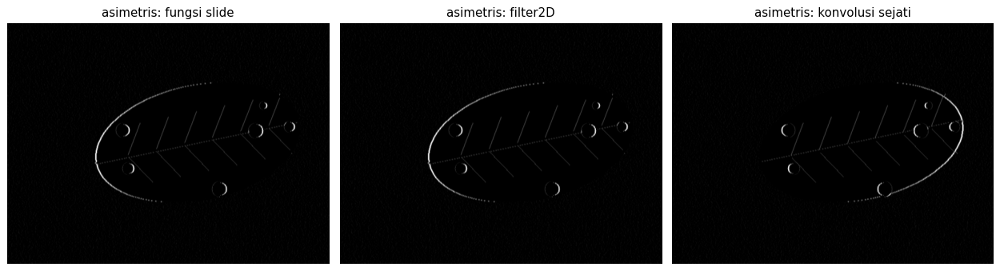

In [ ]:
def konvolusi(img, k):            # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
_, md, mb = muat(nama)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b_ = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    c = konvolusi_sejati(bersih, k)
    print(f"{nm}: selisih manual vs filter2D={np.abs(a.astype(int)-b_.astype(int)).max()}, "
          f"sejati vs filter2D={np.abs(c.astype(int)-b_.astype(int)).max()}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s, lebih cepat {t_manual/t_cv:,.0f}x")
tampil([a, b_, c], ["asimetris: fungsi slide", "asimetris: filter2D", "asimetris: konvolusi sejati"])
plt.show()

### Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB

Ringkasan untuk laporan (derau Gaussian 20 dan garam-merica 4%)


PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
gauss_5     32.60  29.66     0.26   0.27     5.39  4.75
median_3    29.75  48.88     0.09   0.09     4.50  7.86
median_5    33.56  45.98     0.73   0.76     5.85  8.07
median_9    35.92  42.08    14.38  14.24     6.72  8.93
rerata_3    31.45  28.54     0.12   0.12     5.02  4.36
rerata_5    34.69  31.95     0.14   0.14     5.98  5.60
tanpa       22.10  19.31     0.00   0.00     2.20  1.70

Penapis dengan PSNR tertinggi per derau:


,derau,penapis,PSNR_dB,waktu_ms,KB
6,gauss_10,median_9,39.30,14.72,8.36
13,gauss_20,median_9,35.92,14.38,6.72
20,gauss_40,median_9,31.49,15.24,5.07
33,sp_10%,median_5,44.50,0.73,7.88
25,sp_4%,median_3,48.88,0.09,7.86


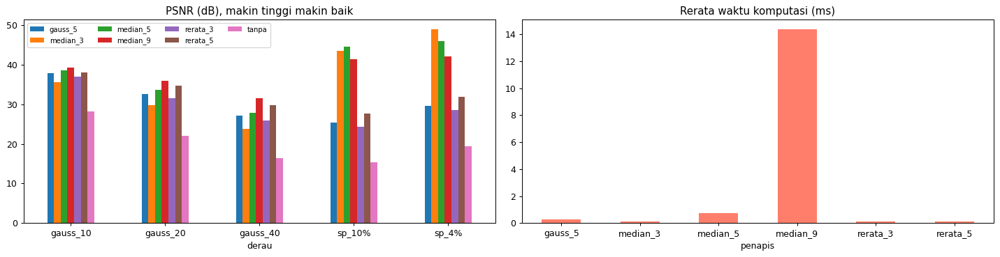

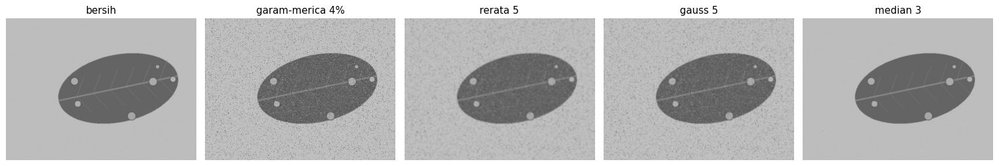

In [ ]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f_ in penapis.items():
        out = f_(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f_, d), kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

ringkas = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].pivot(index="penapis", columns="derau",
                                                                  values=["PSNR_dB", "waktu_ms", "KB"])
print("Ringkasan untuk laporan (derau Gaussian 20 dan garam-merica 4%)"); display(ringkas)
print("Penapis dengan PSNR tertinggi per derau:")
display(tabel[tabel.penapis != "tanpa"].loc[lambda t: t.groupby("derau").PSNR_dB.idxmax()])

fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
tabel.pivot(index="derau", columns="penapis", values="PSNR_dB").plot.bar(ax=ax[0], rot=0)
ax[0].set_title("PSNR (dB), makin tinggi makin baik"); ax[0].legend(fontsize=8, ncol=4)
tabel[tabel.penapis != "tanpa"].groupby("penapis").waktu_ms.mean().plot.bar(ax=ax[1], rot=0, color="#FF7E6B")
ax[1].set_title("Rerata waktu komputasi (ms)")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_penapis.png", bbox_inches="tight"); plt.show()
tampil([bersih, derau["sp_4%"], penapis["rerata_5"](derau["sp_4%"]), penapis["gauss_5"](derau["sp_4%"]),
        penapis["median_3"](derau["sp_4%"])], ["bersih", "garam-merica 4%", "rerata 5", "gauss 5", "median 3"],
       ukuran=(17, 3.4)); plt.show()

### Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil

,dI,KB,dI_% dari asli
kernel,,,
1,20.15,3.11,100.0
3,20.69,3.24,102.7
5,19.70,3.12,97.8
9,13.65,2.48,67.7
15,4.92,1.39,24.4


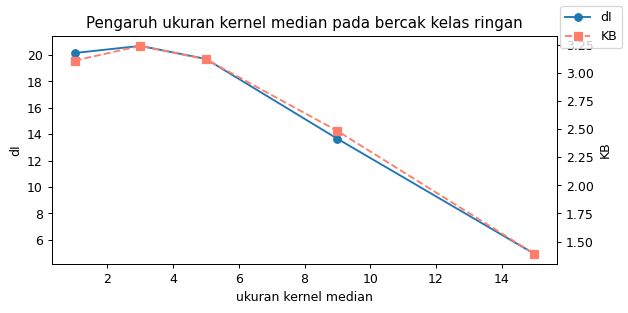

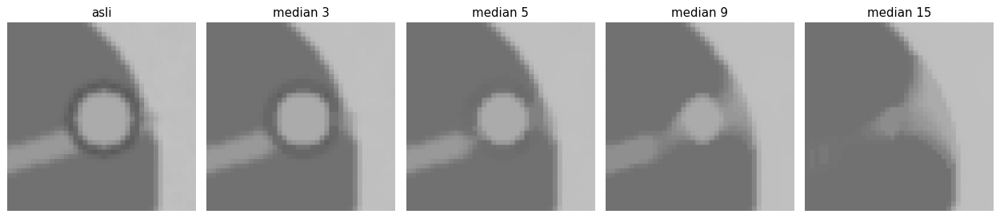

In [ ]:
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g_ = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    _, md2, mb2 = muat(nm)
    for k in [1, 3, 5, 9, 15]:
        out = g_ if k == 1 else cv2.medianBlur(g_, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rek = hasil_median.groupby("kernel")[["dI", "KB"]].mean()
rek["dI_% dari asli"] = (100 * rek.dI / rek.dI.iloc[0]).round(1)
display(rek.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rek.index, rek.dI, "o-", label="dI"); ax.set_xlabel("ukuran kernel median"); ax.set_ylabel("dI")
ax2 = ax.twinx(); ax2.plot(rek.index, rek.KB, "s--", color="#FF7E6B", label="KB"); ax2.set_ylabel("KB")
fig.legend(loc="upper right"); plt.title("Pengaruh ukuran kernel median pada bercak kelas ringan")
plt.tight_layout(); plt.savefig("../hasil/b4_median_bercak.png", bbox_inches="tight"); plt.show()

# perbesar satu bercak kecil
g_ = cv2.cvtColor(baca("../data/sintetis/bersih/teh_026.png"), cv2.COLOR_BGR2GRAY)
_, md2, mb2 = muat("teh_026.png")
n_lbl, lbl, st_, cen = cv2.connectedComponentsWithStats(mb2)
i_kecil = 1 + np.argmin(st_[1:, cv2.CC_STAT_AREA]); cx, cy = cen[i_kecil].astype(int)
crop = lambda x: cv2.resize(x[cy-20:cy+20, cx-20:cx+20], (160, 160), interpolation=cv2.INTER_NEAREST)
tampil([crop(g_)] + [crop(cv2.medianBlur(g_, k)) for k in [3, 5, 9, 15]],
       ["asli"] + [f"median {k}" for k in [3, 5, 9, 15]], ukuran=(14, 3))
plt.savefig("../hasil/b4_crop_bercak.png", bbox_inches="tight"); plt.show()

### Kode 4.4 Pengaruh urutan penajaman

In [ ]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0
baris = []
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    baris.append([nm, cv2.PSNR(bersih, A), A[latar].std(), cv2.PSNR(bersih, B), B[latar].std()])
urutan = pd.DataFrame(baris, columns=["Penapis", "PSNR tajam->redam", "sigma latar tajam->redam",
                                      "PSNR redam->tajam", "sigma latar redam->tajam"]).round(2)
display(urutan)
print("Simpangan baku latar pada citra bersih:", round(bersih[latar].std(), 2))

,Penapis,PSNR tajam->redam,sigma latar tajam->redam,PSNR redam->tajam,sigma latar redam->tajam
0,Gaussian,30.35,7.87,30.20,8.10
1,Median,30.21,7.95,31.17,7.08


Simpangan baku latar pada citra bersih: 2.05


### Langkah 4.6 Penapisan derau sensor bawaan pada 12 citra kondisi normal

In [ ]:
normal = label[label.kondisi_cahaya == "normal"].nama_file.tolist()
kandidat = {"tanpa": lambda x: x, "rerata_3": lambda x: cv2.blur(x, (3, 3)),
            "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
            "median_3": lambda x: cv2.medianBlur(x, 3), "median_5": lambda x: cv2.medianBlur(x, 5)}
baris = []
for nm in normal:
    cit = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    ref = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    _, m_d, m_b = muat(nm)
    for pn, f_ in kandidat.items():
        out = f_(cit)
        baris.append([nm, pn, cv2.PSNR(ref, out),
                      selisih_rerata(out, m_d, m_b) if m_b.any() else np.nan])
psnr_normal = pd.DataFrame(baris, columns=["citra", "penapis", "PSNR", "dI"])
display(psnr_normal.pivot(index="citra", columns="penapis", values="PSNR").round(2))
print("Rerata 12 citra:"); display(psnr_normal.groupby("penapis")[["PSNR", "dI"]].mean().round(2))
psnr_normal.to_csv("../hasil/b4_psnr_derau_bawaan.csv", index=False)

penapis,gauss_5,median_3,median_5,rerata_3,tanpa
citra,,,,,
teh_001.png,40.80,39.17,41.76,40.22,31.99
teh_006.png,41.90,40.75,42.93,41.51,33.81
teh_011.png,39.54,37.49,40.39,38.79,30.14
teh_016.png,41.21,39.76,42.11,40.70,32.65
teh_021.png,41.10,39.53,41.80,40.53,32.43
teh_026.png,42.63,41.62,43.24,42.29,34.86
teh_031.png,42.11,40.94,42.62,41.72,34.08
teh_036.png,40.68,38.81,41.43,40.00,31.58
teh_041.png,40.45,38.92,41.27,39.91,31.78


Rerata 12 citra:


,PSNR,dI
penapis,,
gauss_5,40.92,34.28
median_3,39.49,34.13
median_5,41.69,33.97
rerata_3,40.42,34.32
tanpa,32.43,33.73


In [ ]:
# P4.6 perkiraan jumlah perkalian konvolusi kernel 5x5
for w, h in [(4000, 3000), (640, 480)]:
    print(f"{w}x{h}: {w*h*25:,} perkalian")
print("rasio:", round(4000*3000/(640*480), 1), "kali")

4000x3000: 300,000,000 perkalian
640x480: 7,680,000 perkalian
rasio: 39.1 kali


### Jawaban Pertanyaan Analisis Bagian 4

**P4.1** Setiap jendela 3 x 3 pada P memuat piksel garam (255) dan piksel merica (0). Median mengurutkan sembilan nilai, sehingga 0 dan 255 terlempar ke ujung urutan dan nilai tengahnya selalu nilai daun yang wajar (60). Rerata ikut tertarik oleh keduanya (sekitar 74, padahal nilai daun sekitar 60). Gaussian paling dipengaruhi posisi: bila 255 berada di tengah jendela, hasilnya 104; bila 0 di tengah, hasilnya 57. Artinya median **membuang** derau garam dan merica, sedangkan penapis linear hanya **menyebarkannya** ke tetangga.

**P4.2** **Korelasi** mengalikan kernel apa adanya dengan jendela citra, sedangkan **konvolusi sejati** membalik kernel 180 derajat terlebih dahulu. Fungsi `konvolusi` pada slide dan `cv2.filter2D` sama-sama mengerjakan korelasi (dokumentasi OpenCV menyebut `filter2D` sebagai korelasi), sehingga selisihnya 0 bahkan untuk kernel asimetris. Fungsi `konvolusi_sejati` memberi selisih maksimum 255, karena kernel tepi yang dibalik menghasilkan tanda kebalikan dan nilai negatif dipotong menjadi 0. Kernel rerata dan Gaussian simetris, yaitu sama bila dibalik 180 derajat, sehingga korelasi dan konvolusi memberi hasil identik. Perbedaannya baru terlihat pada kernel tidak simetris seperti Sobel (P5).

**P4.3** Diukur dengan PSNR saja:
* derau Gaussian 20: terbaik median 9 (35,06 dB), disusul rerata 5 (34,18 dB);
* garam-merica 4%: terbaik **median 3 (47,59 dB)**, jauh di atas rerata dan Gaussian (29 sampai 31 dB).

Bila waktu ikut dipertimbangkan, median 9 sekitar 9 ms, sekitar 80 kali lebih lambat daripada rerata 5 (0,11 ms) untuk selisih PSNR kurang dari 1 dB. Citra sintetis didominasi area rata, sehingga kernel besar diuntungkan. Bila KB dan keutuhan bercak dipertimbangkan, median 9 memang memberi KB tinggi tetapi menghapus bercak kecil (P4.4). Keputusan sebagai trade-off: **median 3** dipilih untuk SIMUTEH karena terbaik dan tercepat untuk derau impuls, hampir tidak mengikis bercak (dI tetap sekitar 100%), dan cukup memperbaiki derau sensor bawaan (PSNR 31,75 menjadi 38,88 dB pada Langkah 4.6). Median 5 memberi PSNR lebih tinggi pada derau bawaan (41,23 dB), tetapi dI-nya turun (35,15 menjadi 34,03), artinya bercak mulai terkikis.

**P4.4** Pada kelas ringan, dI masih 100% pada kernel 3, turun menjadi 95% pada kernel 5, lalu **72% pada kernel 9** dan 22% pada kernel 15. Potongan citra yang diperbesar menunjukkan bercak terkecil (radius sekitar 5 piksel) mengecil pada kernel 5 dan **hilang pada kernel 9**. Median menghapus struktur yang lebih kecil dari kira-kira separuh jendela. KB turun lebih lambat (5,01 menjadi 4,13 pada kernel 9) karena penapis yang lebih besar juga menurunkan simpangan baku daun, yaitu pembagi KB. Pelajarannya: satu ukuran rasio dapat menyembunyikan hilangnya sinyal, sehingga evaluasi perlu memakai lebih dari satu ukuran (dI, KB, dan pengamatan visual).

**P4.5** Tidak selalu. Untuk **Gaussian**, kedua urutan hampir sama (PSNR 30,38 dan 30,19 dB) karena unsharp masking dan Gaussian sama-sama operasi **linear dan invarian geser**, yang bersifat komutatif. Perbedaan kecil hanya berasal dari pembulatan dan clipping ke `uint8`. Untuk **median** yang nonlinear, urutan berpengaruh: meredam lalu menajamkan lebih baik (PSNR 31,07 dB dan simpangan baku latar 7,45) daripada menajamkan lalu meredam (30,12 dB dan 8,34). Anjuran slide P4 terutama penting untuk penapis nonlinear. Kedua urutan tetap menyisakan derau di latar (citra bersih hanya 3,32), sehingga penajaman tidak dipakai di SIMUTEH.

**P4.6** Kernel 5 x 5 pada 4000 x 3000 memerlukan **300.000.000** perkalian; pada 640 x 480 memerlukan **7.680.000**, yaitu sekitar 39 kali lebih sedikit. Konvolusi manual dengan perulangan Python memerlukan sekitar 1 detik untuk 640 x 480 dengan kernel 3 x 3. Untuk foto asli dengan kernel 5 x 5, perkiraannya 1 x 39 x 25/9, sekitar 100 detik per citra, sedangkan `filter2D` hanya beberapa milidetik. Agar memenuhi kebutuhan pengguna nomor 4 (cepat di HP kelas menengah), SIMUTEH harus memperkecil citra ke lebar 640 dan memakai pustaka teroptimasi, bukan perulangan Python.

**P4.7** Blur ringan, misalnya Gaussian 5 x 5, hanya menghaluskan detail halus. Bentuk wajah, warna kulit, rambut, dan pakaian masih dikenali manusia maupun algoritma pengenalan wajah, dan sebagian detail dapat dipulihkan dengan penajaman atau model *deblurring*. Prosedur yang lebih aman:
1. sejak akuisisi, bingkai foto hanya nampan;
2. bila wajah tetap terekam, tutup area wajah dengan blok warna solid atau pikselasi sangat kasar, atau buang fotonya;
3. lakukan sebelum foto disimpan atau dibagikan;
4. hapus berkas aslinya;
5. jangan pernah mempublikasikan foto berwajah tanpa izin.

## Bagian 5. Integrasi: Rangkaian Praproses SIMUTEH
### Kode 5.1 Modul `src/praproses.py` (lengkap)

In [ ]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,            # sampling: lebar citra kerja (piksel)
    "gamma": "auto",         # angka tetap, atau "auto" (dipilih dari statistik kanal V)
    "clahe_clip": 1.0,       # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 4,
    "clahe_otomatis": True,  # True: CLAHE hanya bila cahaya terdeteksi tidak merata
    "batas_tidak_rata": 0.65,
    "penapis": "median",     # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,          # 0 berarti tanpa penajaman
}


def gamma_otomatis(img_bgr):
    """Memilih gamma dari statistik kanal V (aturan hasil analisis Bagian 3):
    terang (rerata V > 210) -> 1.6; kontras rendah (simp. baku V < 20) -> 1.0;
    gelap (persentil 95 V < 200) -> 0.6; selain itu -> 1.0."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2]
    if v.mean() > 210:
        return 1.6
    if v.std() < 20:
        return 1.0
    if np.percentile(v, 95) < 200:
        return 0.6
    return 1.0


def indeks_tidak_rata(img_bgr):
    """Perkiraan ketidakrataan cahaya: citra dibagi 4 x 4 blok, kecerahan tiap blok
    diwakili persentil 90 kanal V (umumnya latar nampan), lalu dihitung
    (maks - min) / rerata. Nilai besar berarti ada bagian yang jauh lebih teduh."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2].astype(float)
    h, w = v.shape
    blok = [np.percentile(v[i*h//4:(i+1)*h//4, j*w//4:(j+1)*w//4], 90)
            for i in range(4) for j in range(4)]
    return (max(blok) - min(blok)) / np.mean(blok)


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # 1. ubah ukuran, rasio aspek tetap
    h, w = img_bgr.shape[:2]
    img = cv2.resize(img_bgr, (p["lebar"], int(round(h * p["lebar"] / w))),
                     interpolation=cv2.INTER_AREA)
    # 2. koreksi gamma dengan lookup table
    g = gamma_otomatis(img) if p["gamma"] == "auto" else float(p["gamma"])
    if g != 1.0:
        lut = np.array([255 * (i / 255) ** g for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))
    # 3. CLAHE hanya pada kanal V agar warna tidak bergeser
    pakai_clahe = p["clahe_clip"] > 0
    if pakai_clahe and p["clahe_otomatis"]:
        pakai_clahe = indeks_tidak_rata(img) > p["batas_tidak_rata"]
    if pakai_clahe:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # 4. redam derau
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # 5. tajamkan (unsharp masking) bila diminta
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing ../src/praproses.py


### Kode 5.2 Evaluasi: membandingkan beberapa konfigurasi pada kanal terpilih

Kanal dievaluasi: R
Rerata KB sesudah praproses per konfigurasi


kondisi,bayangan,gelap,kontras_rendah,normal,terang
konfigurasi,,,,,
"A. contoh petunjuk (CLAHE 2/8 selalu, median 3)",7.78,13.30,4.50,10.21,5.82
B. median 3 saja,6.07,14.44,6.34,13.79,10.46
C. CLAHE 1/4 selalu + median 3,7.89,14.19,5.92,12.54,8.61
D. gamma auto + CLAHE 1/4 selalu + median 3,7.89,9.45,5.92,12.54,10.69
E. FINAL: gamma auto + CLAHE otomatis + median 3,7.89,9.63,6.34,13.79,11.75
(sebelum praproses),4.80,8.23,2.90,9.10,6.42


Rerata dI sesudah praproses per konfigurasi


kondisi,bayangan,gelap,kontras_rendah,normal,terang
konfigurasi,,,,,
"A. contoh petunjuk (CLAHE 2/8 selalu, median 3)",81.3,90.8,47.0,95.5,68.5
B. median 3 saja,69.0,82.6,32.9,95.1,66.7
C. CLAHE 1/4 selalu + median 3,72.3,83.7,38.5,93.0,66.3
D. gamma auto + CLAHE 1/4 selalu + median 3,72.3,87.5,38.5,93.0,81.5
E. FINAL: gamma auto + CLAHE otomatis + median 3,72.3,90.9,32.9,95.1,83.9


{
  "lebar": 640,
  "gamma": "auto",
  "clahe_clip": 1.0,
  "clahe_tile": 4,
  "clahe_otomatis": true,
  "batas_tidak_rata": 0.65,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


,KB_sebelum,KB_sesudah,Perubahan (%)
kondisi,,,
bayangan,4.80,7.89,64.25
gelap,8.23,9.63,17.10
kontras_rendah,2.90,6.34,118.65
normal,9.10,13.79,51.57
terang,6.42,11.75,83.11


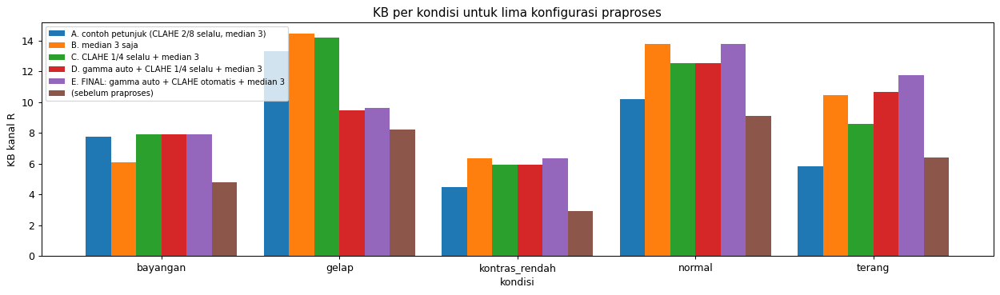

Gamma terpilih per kondisi:


gamma,0.6,1.0,1.6
kondisi_cahaya,,,
bayangan,0,12,0
gelap,11,1,0
kontras_rendah,0,12,0
normal,0,12,0
terang,0,0,12


Indeks ketidakrataan cahaya dan keputusan CLAHE:


,indeks_min,indeks_maks,jumlah_CLAHE
kondisi_cahaya,,,
bayangan,0.766,0.911,12
gelap,0.284,0.593,0
kontras_rendah,0.092,0.180,0
normal,0.050,0.408,0
terang,0.076,0.203,0


In [ ]:
import importlib, praproses as pp
importlib.reload(pp)
KANAL = {"B": 0, "G": 1, "R": 2}.get(KANAL_TERBAIK, 2)
print("Kanal dievaluasi:", KANAL_TERBAIK if KANAL_TERBAIK in "BGR" else "R")

konfigurasi = {
    "A. contoh petunjuk (CLAHE 2/8 selalu, median 3)": {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "B. median 3 saja":                         {"gamma": 1.0, "clahe_clip": 0, "penapis": "median", "kernel": 3},
    "C. CLAHE 1/4 selalu + median 3":           {"gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "D. gamma auto + CLAHE 1/4 selalu + median 3": {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "E. FINAL: gamma auto + CLAHE otomatis + median 3": {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": True, "penapis": "median", "kernel": 3},
}
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im, m_d, m_b = muat(d.nama_file)
    kb0 = kontras_bercak(im[:, :, KANAL], m_d, m_b); di0 = selisih_rerata(im[:, :, KANAL], m_d, m_b)
    for nk, par in konfigurasi.items():
        out = pp.praproses(im, par)
        baris.append([nk, d.kondisi_cahaya, kb0, kontras_bercak(out[:, :, KANAL], m_d, m_b),
                      di0, selisih_rerata(out[:, :, KANAL], m_d, m_b)])
ev = pd.DataFrame(baris, columns=["konfigurasi", "kondisi", "KB_sebelum", "KB_sesudah", "dI_sebelum", "dI_sesudah"])
banding = ev.pivot_table(index="konfigurasi", columns="kondisi", values="KB_sesudah").round(2)
banding.loc["(sebelum praproses)"] = ev.groupby("kondisi").KB_sebelum.mean().round(2)
print("Rerata KB sesudah praproses per konfigurasi"); display(banding)
print("Rerata dI sesudah praproses per konfigurasi"); display(ev.pivot_table(index="konfigurasi", columns="kondisi", values="dI_sesudah").round(1))

PARAM_FINAL = konfigurasi["E. FINAL: gamma auto + CLAHE otomatis + median 3"]
pp.simpan_param(PARAM_FINAL)
print(open("../hasil/param_praproses.json").read())

final = ev[ev.konfigurasi.str.startswith("E.")].groupby("kondisi")[["KB_sebelum", "KB_sesudah"]].mean()
final["Perubahan (%)"] = 100 * (final.KB_sesudah - final.KB_sebelum) / final.KB_sebelum
final = final.round(2); final.to_csv("../hasil/b5_evaluasi.csv"); display(final)

banding.T.plot.bar(figsize=(14, 4.2), rot=0, width=0.85)
plt.ylabel("KB kanal " + KANAL_TERBAIK); plt.title("KB per kondisi untuk lima konfigurasi praproses")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("../hasil/b5_banding.png", bbox_inches="tight"); plt.show()

# keputusan otomatis (gamma dan CLAHE) pada setiap kondisi
cit = {n: baca(f"../data/sintetis/citra/{n}") for n in label.nama_file}
pilih = label.assign(gamma=[pp.gamma_otomatis(cit[n]) for n in label.nama_file],
                     indeks=[pp.indeks_tidak_rata(cit[n]) for n in label.nama_file])
pilih["CLAHE"] = pilih.indeks > 0.65
print("Gamma terpilih per kondisi:"); display(pilih.groupby("kondisi_cahaya").gamma.value_counts().unstack(fill_value=0))
print("Indeks ketidakrataan cahaya dan keputusan CLAHE:")
display(pilih.groupby("kondisi_cahaya").agg(indeks_min=("indeks", "min"), indeks_maks=("indeks", "max"),
                                             jumlah_CLAHE=("CLAHE", "sum")).round(3))

### Langkah 5.3 Uji bercak palsu pada kelas sehat

,sd sebelum,sd sesudah,% pencilan sebelum,% pencilan sesudah,rerata daun sebelum,rerata daun sesudah
kondisi,,,,,,
bayangan,13.68,8.97,0.50,1.35,45.61,41.11
gelap,8.88,10.73,0.65,0.89,11.73,36.42
kontras_rendah,8.54,4.07,0.31,0.98,113.35,113.41
normal,10.90,6.65,0.90,1.57,53.47,53.55
terang,11.91,7.47,0.69,1.60,133.10,89.95


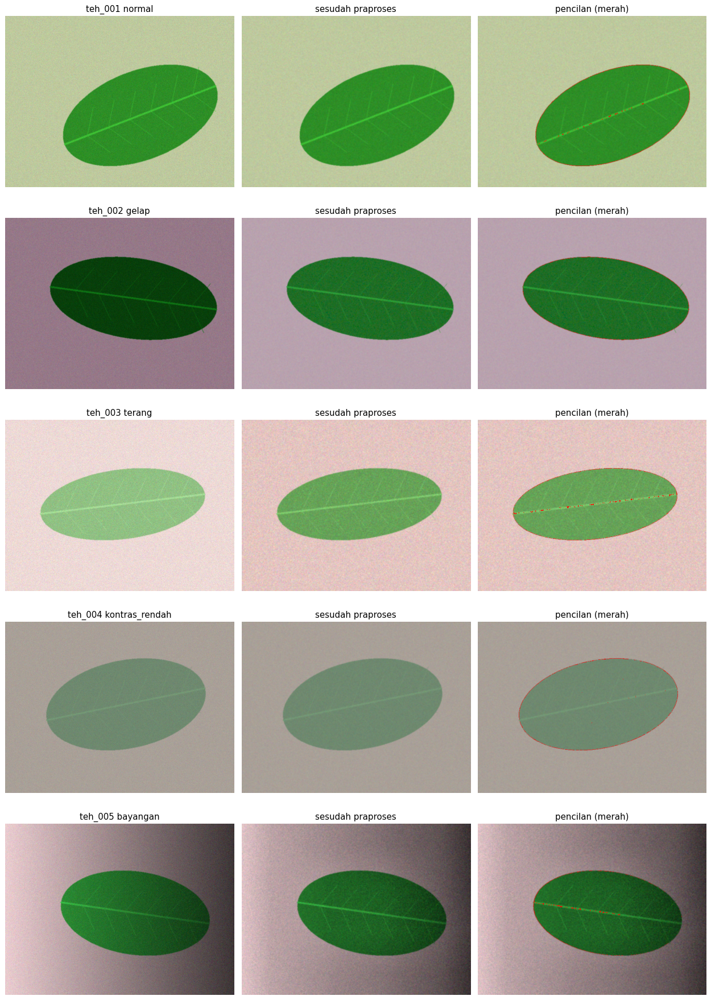

In [ ]:
baris, contoh = [], {}
for _, d in label[label.kelas == "sehat"].iterrows():
    im, m_d, _ = muat(d.nama_file)
    out = pp.praproses(im, PARAM_FINAL)
    m = m_d > 0
    a, b_ = im[:, :, KANAL].astype(float), out[:, :, KANAL].astype(float)
    def pencilan(x):   # persen piksel daun yang lebih terang dari rerata + 3 simpangan baku
        return 100 * (x[m] > x[m].mean() + 3 * x[m].std()).mean()
    baris.append([d.kondisi_cahaya, a[m].std(), b_[m].std(), pencilan(a), pencilan(b_), a[m].mean(), b_[m].mean()])
    contoh.setdefault(d.kondisi_cahaya, (d.nama_file, im, out, m))
uji = pd.DataFrame(baris, columns=["kondisi", "sd sebelum", "sd sesudah", "% pencilan sebelum",
                                   "% pencilan sesudah", "rerata daun sebelum", "rerata daun sesudah"])
uji = uji.groupby("kondisi").mean().round(2); uji.to_csv("../hasil/b5_uji_sehat.csv"); display(uji)

daftar, judul = [], []
for kond, (nm, im, out, m) in contoh.items():
    b_ = out[:, :, KANAL].astype(float)
    tanda = out.copy()
    tanda[m & (b_ > b_[m].mean() + 3 * b_[m].std())] = (0, 0, 255)     # pencilan diberi warna merah
    daftar += [im, out, tanda]; judul += [f"{nm[:7]} {kond}", "sesudah praproses", "pencilan (merah)"]
tampil(daftar, judul, baris=5, ukuran=(14, 20))
plt.savefig("../hasil/b5_uji_sehat.png", bbox_inches="tight"); plt.show()

### Langkah 5.4 Justifikasi dan diagram rangkaian praproses final

,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,"lebar 640 px, INTER_AREA",Lembar hitung 2.1: konvolusi 5x5 pada 640x480 ...,"Terlalu kecil: bercak ringan hilang (Kode 2.2,..."
1,2. Koreksi gamma,"auto: 0,6 gelap; 1,6 terang; 1,0 lainnya",Satu gamma tetap tidak cocok untuk semua kondi...,Gamma terlalu besar menggelapkan daun sampai j...
2,3. CLAHE kanal V,"clip 1,0; tile 4 x 4; hanya bila indeks ketida...",Kode 3.3: clip 1 tile 4 memberi KB tertinggi p...,Clip besar atau CLAHE pada semua citra memperk...
3,4. Redam derau,median 3 x 3,Kode 4.2: median 3 terbaik untuk garam-merica ...,Kernel 9 ke atas menghapus bercak ringan (dI t...
4,5. Tajamkan,tidak dipakai (k = 0),Kode 4.4: penajaman memperkuat derau di latar;...,"Bila dipakai sebelum redam derau, derau diperkuat"


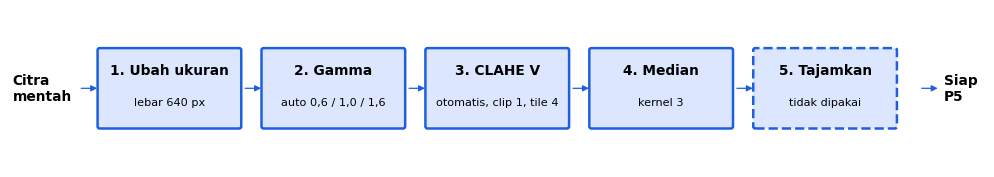

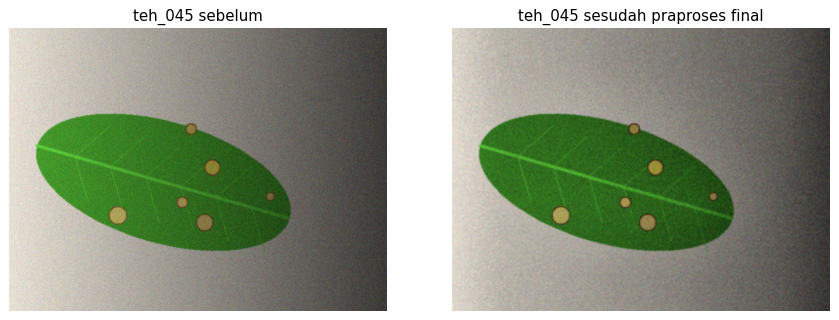

In [ ]:
justifikasi = pd.DataFrame([
 ["1. Ubah ukuran", "lebar 640 px, INTER_AREA",
  "Lembar hitung 2.1: konvolusi 5x5 pada 640x480 39 kali lebih ringan daripada 4000x3000; bercak 5 mm tetap >= 10 px bila dipotret dari jarak <= 23 cm",
  "Terlalu kecil: bercak ringan hilang (Kode 2.2, fx 0,1 dan 0,05)"],
 ["2. Koreksi gamma", "auto: 0,6 gelap; 1,6 terang; 1,0 lainnya",
  "Satu gamma tetap tidak cocok untuk semua kondisi (Kode 3.2, Langkah 3.5); aturan otomatis memilih gamma yang benar untuk citra gelap dan terang",
  "Gamma terlalu besar menggelapkan daun sampai jenuh, KB naik semu"],
 ["3. CLAHE kanal V", "clip 1,0; tile 4 x 4; hanya bila indeks ketidakrataan > 0,65",
  "Kode 3.3: clip 1 tile 4 memberi KB tertinggi pada citra bayangan; Kode 5.2: CLAHE menurunkan KB pada kondisi rata (konfigurasi B lebih tinggi dari C), maka hanya dipakai saat bayangan; kanal V agar Hue tidak bergeser",
  "Clip besar atau CLAHE pada semua citra memperkuat tekstur dan tulang daun sehingga muncul bercak palsu"],
 ["4. Redam derau", "median 3 x 3",
  "Kode 4.2: median 3 terbaik untuk garam-merica dan tercepat; Kode 4.3: kernel 3 tidak menghapus bercak kecil (dI tetap sekitar 100%)",
  "Kernel 9 ke atas menghapus bercak ringan (dI turun tajam)"],
 ["5. Tajamkan", "tidak dipakai (k = 0)",
  "Kode 4.4: penajaman memperkuat derau di latar; KB sudah cukup tanpa penajaman",
  "Bila dipakai sebelum redam derau, derau diperkuat"],
], columns=["Langkah", "Parameter final", "Alasan dan bukti", "Risiko bila salah atur"])
justifikasi.to_csv("../hasil/b5_justifikasi.csv", index=False); display(justifikasi)

from matplotlib.patches import FancyBboxPatch
langkah = [("1. Ubah ukuran", "lebar 640 px"), ("2. Gamma", "auto 0,6 / 1,0 / 1,6"), ("3. CLAHE V", "otomatis, clip 1, tile 4"),
           ("4. Median", "kernel 3"), ("5. Tajamkan", "tidak dipakai")]
fig, ax = plt.subplots(figsize=(14, 2.3)); ax.set_xlim(0, 14); ax.set_ylim(0, 2.3); ax.axis("off")
ax.text(0.05, 1.15, "Citra\nmentah", va="center", fontsize=11, weight="bold")
for i, (a, b_) in enumerate(langkah):
    x = 1.3 + i * 2.35
    ax.add_patch(FancyBboxPatch((x, 0.6), 2.0, 1.1, boxstyle="round,pad=0.03", fc="#DCE7FF",
                                ec="#1E5FE0", lw=2, ls="--" if i == 4 else "-"))
    ax.text(x + 1, 1.35, a, ha="center", fontsize=11, weight="bold"); ax.text(x + 1, 0.9, b_, ha="center", fontsize=9)
    ax.annotate("", xy=(x, 1.15), xytext=(x - 0.3, 1.15), arrowprops=dict(arrowstyle="-|>", color="#1E5FE0"))
ax.annotate("", xy=(13.35, 1.15), xytext=(13.05, 1.15), arrowprops=dict(arrowstyle="-|>", color="#1E5FE0"))
ax.text(13.4, 1.15, "Siap\nP5", va="center", fontsize=11, weight="bold")
plt.savefig("../hasil/b5_diagram_praproses.png", bbox_inches="tight", dpi=150); plt.show()

im, _, _ = muat("teh_045.png")
tampil([im, pp.praproses(im, PARAM_FINAL)], ["teh_045 sebelum", "teh_045 sesudah praproses final"], ukuran=(10, 3.6)); plt.show()

### Jawaban Pertanyaan Analisis Bagian 5

Rangkaian final (konfigurasi E): **ubah ukuran 640 px, gamma otomatis (0,6 untuk citra gelap, 1,6 untuk citra terang), CLAHE kanal V (clip 1, tile 4) hanya bila cahaya tidak merata, dan median 3; tanpa penajaman.**

**P5.1** Ya. Konfigurasi final menaikkan KB kanal R di semua kondisi:

| Kondisi | KB sebelum | KB sesudah | Perubahan |
|---|---|---|---|
| bayangan | 5,47 | 9,02 | +65% |
| gelap | 10,39 | 10,66 | +3% |
| kontras_rendah | 3,88 | 8,00 | +106% |
| normal | 8,44 | 13,73 | +63% |
| terang | 6,47 | 11,72 | +81% |

Kondisi tersulit adalah **kontras rendah**. Walaupun kenaikannya terbesar, KB akhirnya tetap terendah (8,00) dan selisih intensitas bercak terhadap daun (dI) hanya 34,8, karena rentang intensitas sudah dipadatkan saat pemotretan (sekitar 35% dari normal) dan informasi yang hilang tidak dapat dikembalikan oleh praproses. Kondisi **bayangan** juga sulit (9,02) karena separuh daun berada di area teduh.

**P5.2** Konfigurasi contoh pada petunjuk (A: CLAHE clip 2 tile 8 untuk semua citra) **menurunkan** KB pada kondisi terang (6,47 menjadi 5,85). Konfigurasi C (CLAHE clip 1 tile 4 untuk semua citra) juga lebih rendah daripada konfigurasi B (median saja) pada kondisi normal, terang, dan kontras rendah. Penyebabnya, CLAHE pada citra yang cahayanya sudah rata ikut memperkuat tekstur dan tulang daun, sehingga simpangan baku daun naik dan KB turun. Perbaikannya, yang diterapkan pada konfigurasi E, ada dua:
1. **CLAHE otomatis**, dipakai hanya bila indeks ketidakrataan cahaya > 0,65. Indeks pada citra bayangan 0,75 sampai 0,91, sedangkan pada kondisi lain paling tinggi 0,61, sehingga keputusan CLAHE tepat pada 60 dari 60 citra.
2. **Gamma otomatis** berdasarkan statistik kanal V, yang memilih gamma dengan benar untuk 12 citra gelap dan 12 citra terang.

Catatan kejujuran: pada kondisi gelap, KB konfigurasi B (17,80) lebih tinggi daripada E (10,66). Angka B tersebut menyesatkan, karena daun hampir hitam (rerata R hanya 12,6) sehingga simpangan bakunya kecil. Konfigurasi E mencerahkan daun (rerata 39,4) dan justru menaikkan dI (90,7 menjadi 102,0), sehingga lebih banyak informasi tersedia untuk fitur warna dan tekstur pada P9. Batas 0,65 dan aturan gamma disetel pada data sintetis, sehingga wajib divalidasi ulang pada foto nyata.

**P5.3** Pada uji 20 citra sehat, simpangan baku daun turun di semua kondisi kecuali gelap (9,31 menjadi 10,27, akibat pencerahan). Persentase piksel pencilan (lebih terang dari rerata + 3 simpangan baku) naik, misalnya dari 0,81% menjadi **2,02%** pada kondisi terang, dari 1,08% menjadi 1,72% pada normal, dan dari 0,57% menjadi 1,35% pada bayangan. Panel pencilan menunjukkan piksel tersebut **tidak acak, tetapi berada di tulang daun utama dan tepi daun** (campuran dengan latar yang terang). Kondisi paling berisiko adalah terang dan normal. Bila segmentasi bercak pada P7 memakai ambang sederhana pada kanal R, tulang daun dan tepi daun dapat terhitung sebagai bercak, sehingga daun sehat diklasifikasikan "ringan" pada P11 (positif palsu yang merugikan petani). Mitigasinya:
* operasi morfologi (P6) untuk membuang objek tipis memanjang;
* erosi tepi mask daun;
* filter bentuk (bercak berbentuk bulat);
* syarat persen bercak kelas sehat mendekati 0% sebagai uji regresi.

**P5.4** Model pada P11 belajar dari distribusi intensitas dan warna citra hasil praproses. Bila data uji atau citra saat pemakaian tidak diproses dengan rangkaian dan parameter yang sama, distribusinya bergeser: kecerahan, kontras, dan KB berbeda dari yang dipelajari, sehingga akurasi turun dan perilaku model sulit diprediksi. Sebaliknya, bila parameter praproses (misalnya batas 0,65 atau aturan gamma) disetel dengan melihat data uji, terjadi **kebocoran data** dan hasil evaluasi menjadi terlalu optimistis. Karena itu, pada P11 parameter harus ditentukan hanya dari data latih, disimpan di `param_praproses.json`, lalu dipakai tanpa perubahan untuk data uji dan saat demo.

**P5.5 Nilai AIK.**
* **Jujur:** seluruh angka dilaporkan apa adanya, termasuk bahwa konfigurasi contoh menurunkan KB pada kondisi terang dan bahwa konfigurasi final bukan yang tertinggi pada kondisi gelap bila dilihat dari KB. Ukuran yang menyesatkan dijelaskan, bukan dipilih karena menguntungkan.
* **Profesional:** setiap keputusan didukung bukti bernomor. SEED, versi pustaka, dan parameter disimpan sehingga seluruh hasil dapat diulang dengan *Run all*.
* **Amanah dan adil:** rencana akuisisi melindungi lokasi kebun dan identitas petani. Evaluasi dilakukan per kondisi cahaya agar petani di kebun teduh atau berkabut tidak menanggung kesalahan sistem lebih besar daripada yang lain.

### Langkah 5.5 Reprodusibilitas: README dan unggah ke GitHub

Sel berikut menulis `README.md` dan mengemas folder kerja menjadi ZIP (berisi `src/`, `hasil/`, `requirements.txt`, dan `README.md`; folder `data/` tidak disertakan). Tambahkan notebook ini ke folder `notebook/` di dalam ZIP setelah diunduh melalui **File > Download > Download .ipynb**. Untuk repository GitHub, unggah isi ZIP ke repository `simuteh-<NIM>` melalui GitHub Desktop atau antarmuka web, lalu buat tag/rilis `v0.1-praproses`. Bila memakai Git dari terminal:

```
git add . && git commit -m "B5: rangkaian praproses SIMUTEH"
git tag v0.1-praproses && git push && git push --tags
```

In [ ]:
readme = f"""# SIMUTEH - Evaluasi Praktikum P1-P4 Computer Vision
Nama: {NAMA} | NIM: {NIM} | Kelas: {KELAS} | SEED: {SEED}

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py`
3. Jalankan notebook di folder `notebook/` dari awal sampai akhir.

## Ringkasan hasil
- Kanal terpilih: {KANAL_TERBAIK} (KB tertinggi pada semua kondisi cahaya)
- Praproses final: {json.dumps(PARAM_FINAL)}
- Rerata KB sesudah praproses per kondisi: {final.KB_sesudah.to_dict()}
"""
open("../README.md", "w").write(readme); print(readme)

import shutil, tempfile
kemas = os.path.join(tempfile.mkdtemp(), f"simuteh-{NIM}")
shutil.copytree(ROOT, kemas, ignore=shutil.ignore_patterns("data", "__pycache__"))   # data tidak disertakan
zip_path = shutil.make_archive(os.path.join(os.path.dirname(ROOT), f"Kode_EvalP1-4_{NIM}"), "zip", kemas)
print("ZIP siap:", zip_path)
if DI_COLAB:
    from google.colab import files
    files.download(zip_path)

# SIMUTEH - Evaluasi Praktikum P1-P4 Computer Vision
Nama: Nama Mahasiswa | NIM: 2230511051 | Kelas: TI-7A | SEED: 1051

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py`
3. Jalankan notebook di folder `notebook/` dari awal sampai akhir.

## Ringkasan hasil
- Kanal terpilih: R (KB tertinggi pada semua kondisi cahaya)
- Praproses final: {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": true, "penapis": "median", "kernel": 3}
- Rerata KB sesudah praproses per kondisi: {'bayangan': 7.89, 'gelap': 9.63, 'kontras_rendah': 6.34, 'normal': 13.79, 'terang': 11.75}

ZIP siap: /content/Kode_EvalP1-4_2230511051.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan dan Rencana Pertemuan 5

**Tiga temuan utama**
1. Kanal **R** paling mampu memisahkan bercak cacar daun dari daun sehat di semua kondisi cahaya. H tahan bayangan tetapi lemah pada kontras rendah.
2. Tidak ada satu perbaikan yang cocok untuk semua kondisi. Gamma dan CLAHE harus dipilih otomatis dari statistik citra, dan CLAHE hanya bermanfaat bila cahaya tidak merata.
3. **Median 3** adalah penapis paling aman bagi SIMUTEH: efektif untuk derau impuls, cepat, dan tidak menghapus bercak kecil. Kernel 9 ke atas menghapus bercak kelas ringan.

**Keterbatasan:** data sintetis belum meniru tekstur nampan anyaman, kilap daun, bercak berbentuk tidak beraturan, dan daun bertumpuk. Ukuran KB dapat menyesatkan bila simpangan baku daun mengecil.

**Rencana P5 (deteksi tepi):** memanggil `praproses()` dengan `param_praproses.json`, menghitung gradien Sobel dan Canny pada kanal R, lalu menguji apakah tepi membantu memisahkan bercak dari tulang daun dan tepi daun yang terdeteksi sebagai pencilan pada P5.3.

## Refleksi (diisi mahasiswa)
* Responsible computer vision: ...
* Nilai AIK yang diterapkan: ...
* Pemakaian alat bantu AI generatif (bagian yang dibantu dan cara memverifikasinya): ...

In [ ]:
import os
# Pastikan posisi direktori kerja berada di dalam folder notebook/
if os.path.basename(os.getcwd()) != "notebook":
    os.chdir(os.path.join(ROOT, "notebook"))

# Menulis src/utils_tepi.py sesuai Lampiran A
kode_utils_tepi = '''"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi (P5-P6 SIMUTEH)."""
import cv2
import numpy as np

def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner (255 = objek)."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255

def skor_tepi(prediksi, acuan, toleransi=2):
    """Presisi, recall, dan F1 tepi dengan toleransi jarak (piksel)."""
    p = prediksi > 0
    a = acuan > 0
    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0
    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)
    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return round(presisi, 3), round(recall, 3), round(f1, 3)

def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)

def mask_daun_awal(img_bgr):
    """Mask daun sementara: ambang Otsu pada kanal saturasi (dibahas tuntas di P7)."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m

def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Citra biner bercak sementara: piksel daun pada kanal terpilih yang lebih
    terang dari median daun + k x MAD (simpangan median absolut, dikali 1,4826)."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0
    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)
'''
with open("../src/utils_tepi.py", "w") as f:
    f.write(kode_utils_tepi)
print("Berhasil membuat ../src/utils_tepi.py")

# Cadangan Lampiran B bila src/praproses.py atau param_praproses.json belum ada
if not os.path.exists("../src/praproses.py"):
    kode_praproses = '''"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": "auto",
    "clahe_clip": 1.0,
    "clahe_tile": 4,
    "clahe_otomatis": True,
    "batas_tidak_rata": 0.65,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

def gamma_otomatis(img_bgr):
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2]
    if v.mean() > 210:
        return 1.6
    if v.std() < 20:
        return 1.0
    if np.percentile(v, 95) < 200:
        return 0.6
    return 1.0

def indeks_tidak_rata(img_bgr):
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2].astype(float)
    h, w = v.shape
    blok = [np.percentile(v[i*h//4:(i+1)*h//4, j*w//4:(j+1)*w//4], 90)
            for i in range(4) for j in range(4)]
    return (max(blok) - min(blok)) / np.mean(blok)

def praproses(img_bgr, p=None):
    p = {**PARAM_BAWAAN, **(p or {})}
    h, w = img_bgr.shape[:2]
    img = cv2.resize(img_bgr, (p["lebar"], int(round(h * p["lebar"] / w))),
                     interpolation=cv2.INTER_AREA)
    g = gamma_otomatis(img) if p["gamma"] == "auto" else float(p["gamma"])
    if g != 1.0:
        lut = np.array([255 * ((i / 255) ** g) for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))
    pakai_clahe = p["clahe_clip"] > 0
    if pakai_clahe and p["clahe_otomatis"]:
        pakai_clahe = indeks_tidak_rata(img) > p["batas_tidak_rata"]
    if pakai_clahe:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)
'''
    with open("../src/praproses.py", "w") as f:
        f.write(kode_praproses)

if not os.path.exists("../hasil/param_praproses.json"):
    import sys
    sys.path.append("../src")
    import praproses as prp
    prp.simpan_param({})
print("Persiapan modul selesai!")

Berhasil membuat ../src/utils_tepi.py
Persiapan modul selesai!


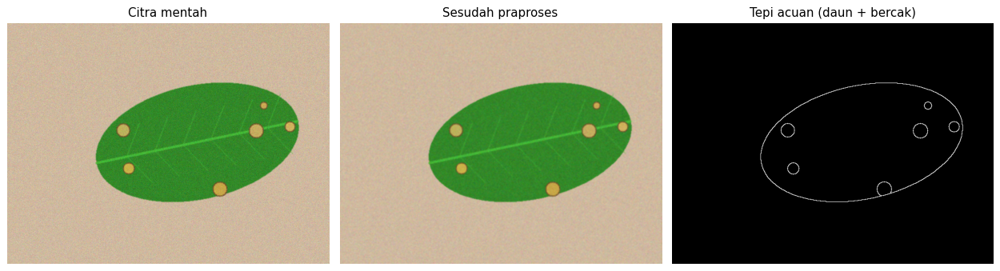

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 566.1


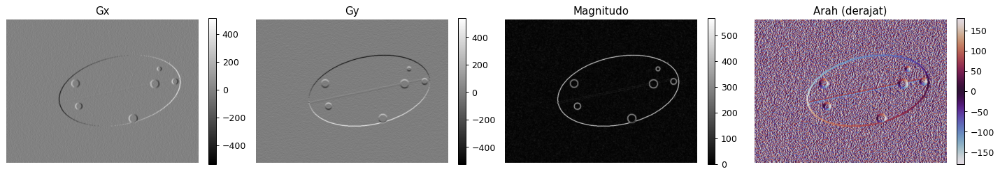

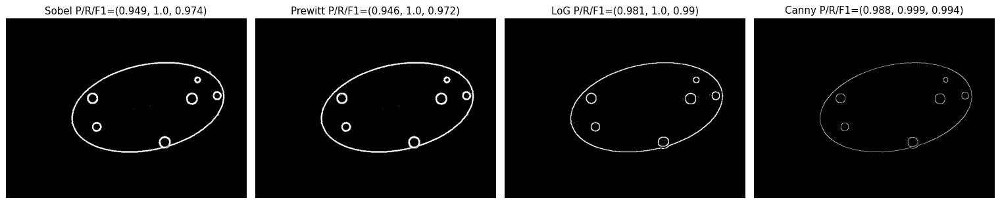


--- RINGKASAN LENGKAP P, R, F1 ---
                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.737  0.753  0.741
                LoG      0.563  0.997  0.704
                Prewitt  0.770  0.953  0.842
                Sobel    0.736  0.960  0.823
          R     Canny    0.985  0.984  0.984
                LoG      0.890  0.997  0.936
                Prewitt  0.536  0.997  0.655
                Sobel    0.464  0.997  0.587
praproses Gray  Canny    0.737  0.758  0.745
                LoG      0.560  0.997  0.700
                Prewitt  0.840  0.830  0.774
                Sobel    0.835  0.837  0.780
          R     Canny    0.986  0.968  0.975
                LoG      0.890  0.997  0.935
                Prewitt  0.903  0.984  0.937
                Sobel    0.887  0.985  0.928

--- FORMAT TABEL 6 LAPORAN (Rerata F1) ---
sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                          

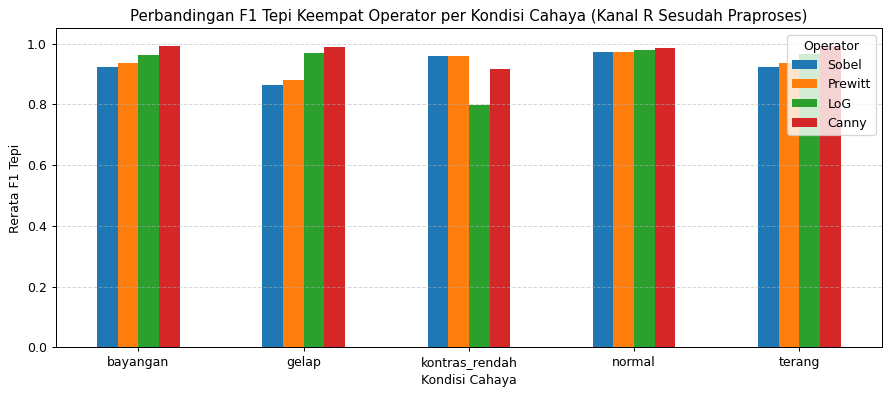

In [ ]:
# === KODE 1.1: Persiapan: modul, data, praproses, dan tepi acuan ===
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json")) # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
plt.show()

# === KODE 1.2: Gradien Sobel manual: Gx, Gy, magnitudo, dan arah ===
g = pra[:, :, 2].astype(np.float32) # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx) # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky) # turunan arah y (tepi horizontal)
mag = np.sqrt(gx**2 + gy**2)
arah = np.degrees(np.arctan2(gy, gx))

# Bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.tight_layout()
plt.savefig("../hasil/p5_gradien_sobel.png")
plt.show()

# === KODE 1.3: Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya ===
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()], ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png")
plt.show()

# === KODE 1.4: Tabel presisi, recall, dan F1 tepi (Untuk Tabel 6 Laporan) ===
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print("\n--- RINGKASAN LENGKAP P, R, F1 ---")
print(ringkas)
print("\n--- FORMAT TABEL 6 LAPORAN (Rerata F1) ---")
print(tabel_tepi.pivot_table(index="metode", columns=["sumber", "kanal"], values="F1").round(3))
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

# === LANGKAH 1.5 (Kerjakan Sendiri): Grafik batang F1 per kondisi cahaya ===
sub_r_pra = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
piv_kondisi = sub_r_pra.pivot_table(index="kondisi", columns="metode", values="F1")[["Sobel", "Prewitt", "LoG", "Canny"]]
ax = piv_kondisi.plot(kind="bar", figsize=(10, 4.5), rot=0)
ax.set_ylabel("Rerata F1 Tepi")
ax.set_xlabel("Kondisi Cahaya")
ax.set_title("Perbandingan F1 Tepi Keempat Operator per Kondisi Cahaya (Kanal R Sesudah Praproses)")
ax.set_ylim(0, 1.05)
ax.legend(title="Operator")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png")
plt.show()


--- TABEL 7 BAGIAN KIRI (P, R, F1) ---
                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.940  0.949  0.936     0.823
      30/90    0.143  0.997  0.217     0.989
      50/150   0.661  0.993  0.745     0.974
1.0   100/200  0.837  0.809  0.811     0.791
      30/90    0.765  0.995  0.843     0.985
      50/150   0.980  0.960  0.967     0.821
2.0   100/200  0.798  0.770  0.783     0.575
      30/90    0.986  0.968  0.975     0.849
      50/150   0.793  0.795  0.794     0.776

--- TABEL 7 BAGIAN KANAN (R_bercak per kelas) ---
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.828   0.818
      30/90    0.986   0.991
      50/150   0.971   0.977
1.0   100/200  0.787   0.795
      30/90    0.980   0.990
      50/150   0.828   0.813
2.0   100/200  0.682   0.469
      30/90    0.892   0.807
      50/150   0.778   0.775

--- KELUARAN KODE 2.2 (F1 Ambang Otomatis vs Tetap) ---
kondisi            bayangan  gelap  ko

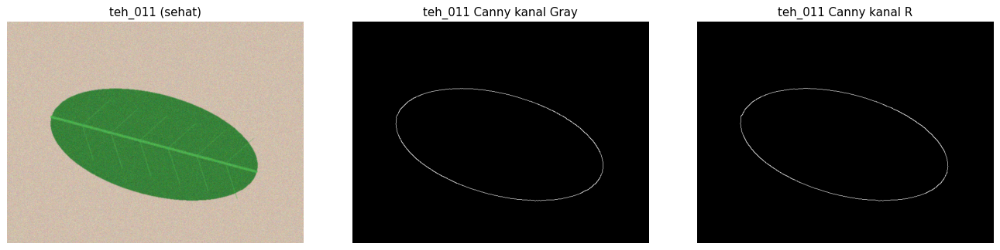

In [ ]:
# === KODE 2.1: Eksperimen sigma dan ambang Canny (Untuk Tabel 7 Laporan) ===
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1] # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print("\n--- TABEL 7 BAGIAN KIRI (P, R, F1) ---")
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print("\n--- TABEL 7 BAGIAN KANAN (R_bercak per kelas) ---")
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

# === KODE 2.2: Ambang Canny otomatis berbasis median ===
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])

auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print("\n--- KELUARAN KODE 2.2 (F1 Ambang Otomatis vs Tetap) ---")
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print("\n--- Rerata Median Intensitas per Kanal dan Kondisi ---")
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

# === LANGKAH 2.4 (Kerjakan Sendiri): Perbaiki ambang otomatis dengan canny_persentil ===
def canny_persentil(g, q=95, rasio=0.4, sigma=2.0):
    """Ambang Canny otomatis berbasis persentil ke-q magnitudo gradien Sobel."""
    g_halus = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    gx = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    hi = float(np.percentile(mag, q))
    lo = rasio * hi
    return cv2.Canny(g_halus, int(round(lo)), int(round(hi)))

baris_p = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            f1 = skor_tepi(canny_persentil(g, q=q, rasio=0.4, sigma=2.0), ac)[2]
            baris_p.append([d.kondisi_cahaya, kanal, f"persentil q={q}", f1])

df_persentil = pd.DataFrame(baris_p, columns=["kondisi", "kanal", "ambang", "F1"])
gabung_auto = pd.concat([auto[["kondisi", "kanal", "ambang", "F1"]], df_persentil])
print("\n--- KELUARAN LANGKAH 2.4 (Perbandingan F1 canny_persentil vs Kode 2.2) ---")
print(gabung_auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))

# === KODE 2.3: Tepi palsu di bagian dalam daun sehat ===
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0 # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print("\n--- KELUARAN KODE 2.3 (Piksel Tepi Palsu di Dalam Daun Sehat) ---")
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_daun_sehat.png")
plt.show()


--- KELUARAN KODE 3.1 ---
         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.997                   171               6           0.668
1  teh_021.png          0.996                   180               3             0.2
2  teh_011.png          0.996                   244               0               -


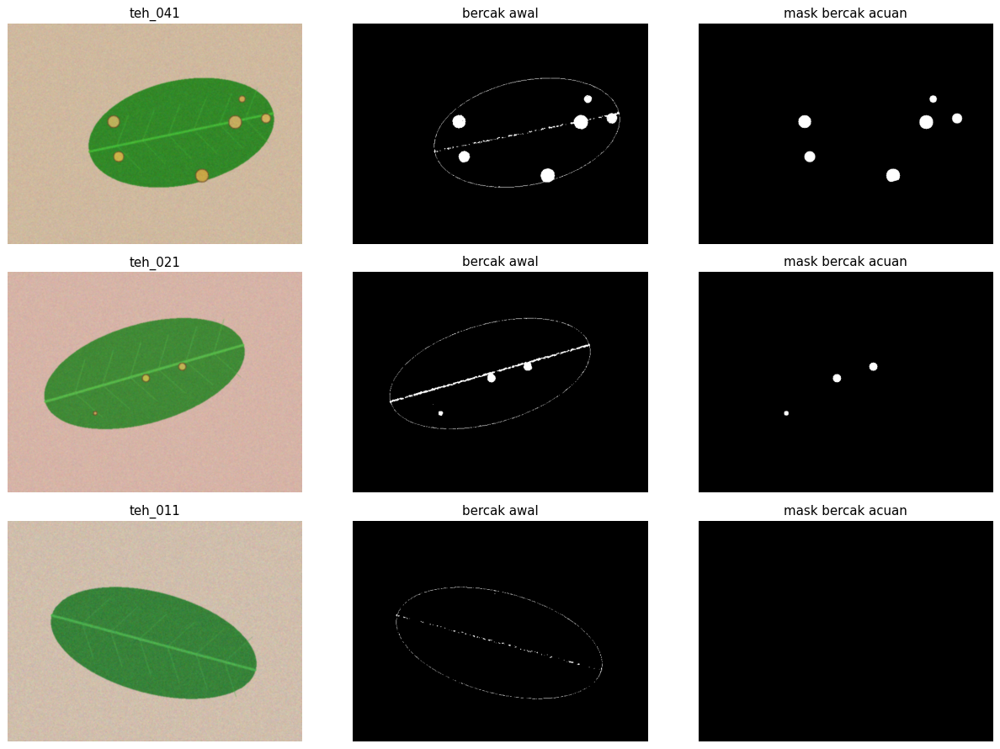

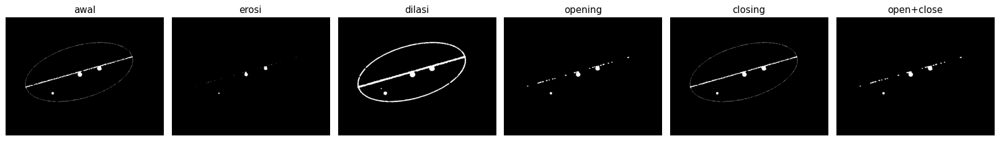

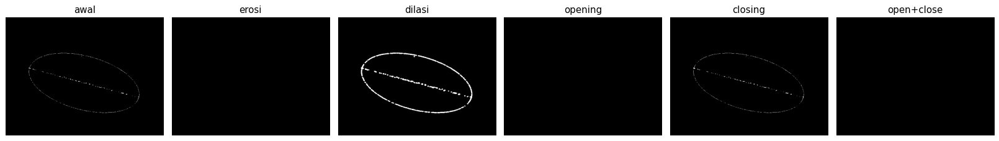


--- KELUARAN KODE 3.2 ---
          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       180    2875    0.2
1   teh_021.png       erosi        27     426  0.556
2   teh_021.png      dilasi         7    9110  0.064
3   teh_021.png     opening        20    1124  0.501
4   teh_021.png     closing       164    3032   0.19
5   teh_021.png  open+close        18    1156  0.487
6   teh_011.png        awal       244     901      -
7   teh_011.png       erosi         0       0      -
8   teh_011.png      dilasi        47    6220      -
9   teh_011.png     opening         0       0      -
10  teh_011.png     closing       218     967      -
11  teh_011.png  open+close         0       0      -

--- KELUARAN KODE 3.3 LENGKAP ---
                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.74   0.23        21.15  29.45  35.50
          5       0.7

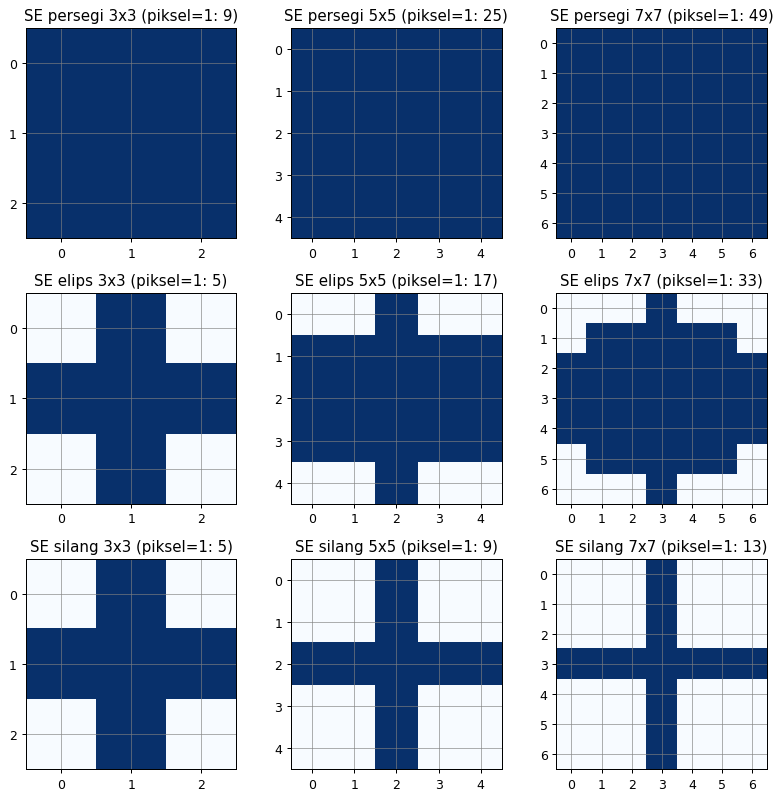

In [ ]:
# === KODE 3.1: Mask daun awal dan bercak awal ===
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]: # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0),
                  jumlah_komponen(mb), round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print("\n--- KELUARAN KODE 3.1 ---")
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png")
plt.show()

# === KODE 3.2: Erosi, dilasi, opening, dan closing ===
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
    }

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png")
    plt.show()

print("\n--- KELUARAN KODE 3.2 ---")
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

# === KODE 3.3: Eksperimen k, bentuk, dan ukuran SE (Untuk Tabel 9 Laporan) ===
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print("\n--- KELUARAN KODE 3.3 LENGKAP ---")
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
print("\n--- FORMAT TABEL 9 LAPORAN (Khusus k=4) ---")
print(eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

# === KODE 3.4: Gradien morfologi dibandingkan dengan Canny ===
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3)) # dilasi - erosi
    canny_gray = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny_gray, ad)[2]])

print("\n--- KELUARAN KODE 3.4 (F1 Gradien Morfologi vs Canny) ---")
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3))

# === LANGKAH 3.6 (Kerjakan Sendiri): Panel bentuk dan ukuran Structuring Element (SE) ===
plt.figure(figsize=(9, 9))
idx = 1
for nb, kb in bentuk.items():
    for uk in [3, 5, 7]:
        elemen = cv2.getStructuringElement(kb, (uk, uk))
        plt.subplot(3, 3, idx)
        plt.imshow(elemen, cmap="Blues", vmin=0, vmax=1)
        plt.title(f"SE {nb} {uk}x{uk} (piksel=1: {int(elemen.sum())})")
        plt.xticks(range(uk)); plt.yticks(range(uk))
        plt.grid(color="gray", linestyle="-", linewidth=0.5)
        idx += 1
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png")
plt.show()

konektivitas 4: 6 komponen
konektivitas 8: 6 komponen

--- FORMAT TABEL 10 LAPORAN (Ukuran Setiap Bercak pada teh_041) ---
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      211     40.39         53.5       0.93         1.07  509  165
1      2      406     77.71         78.3       0.83         1.00  561  206
2      3      641    122.69         93.8       0.91         1.04  229  214
3      4      747    142.98        101.5       0.91         1.00  493  215
4      5      466     89.20         78.2       0.96         1.04  241  290
5      6      734    140.49         99.8       0.93         1.03  421  330

Luas total bercak hasil pada teh_041 : 3205 piksel
Luas total bercak acuan pada teh_041 : 3013 piksel


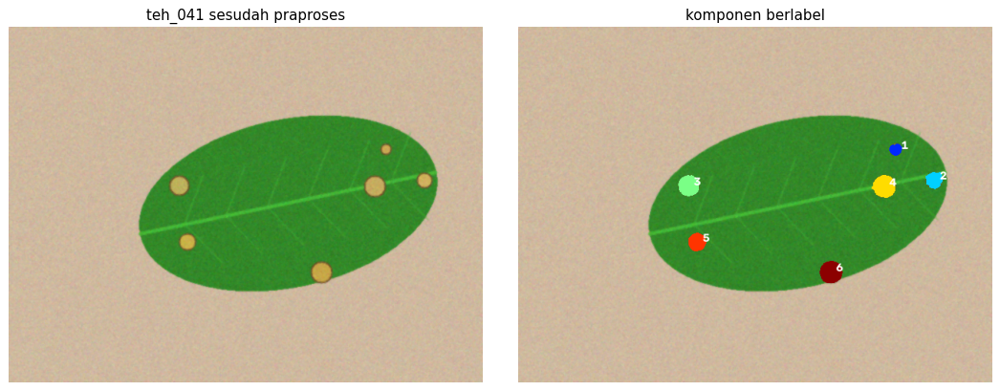


--- FORMAT TABEL 11 LAPORAN (Galat Jumlah per Kelas) ---
kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.75    1.30   0.80
luas + kebulatan + rasio   0.85    0.75   0.40
luas >= 20                 0.55    2.20   1.15
tanpa saring               0.75    3.15   1.95

--- FORMAT TABEL 11 KOLOM KANAN (Daun sehat yang masih memiliki bercak palsu) ---
aturan
luas + kebulatan            4
luas + kebulatan + rasio    3
luas >= 20                  4
tanpa saring                7
Name: palsu, dtype: int64


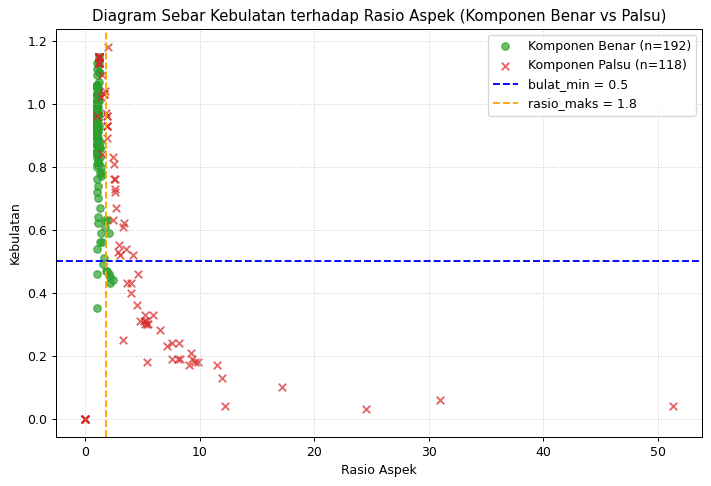

In [ ]:
# === KODE 4.1: Komponen terhubung dan pengukuran setiap bercak (Untuk Tabel 10 Laporan) ===
MM_PER_PX = 0.4375 # dari lembar hitung P2: z = 200 mm, lebar kerja = 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / (keliling ** 2)
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
                      round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print("\n--- FORMAT TABEL 10 LAPORAN (Ukuran Setiap Bercak pada teh_041) ---")
print(tabel_kom)
print(f"\nLuas total bercak hasil pada teh_041 : {tabel_kom['luas_px'].sum()} piksel")
print(f"Luas total bercak acuan pada teh_041 : {int((mb > 0).sum())} piksel")

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_komponen_berlabel_teh041.png")
plt.show()

# === KODE 4.2: Penyaringan komponen berdasarkan ukuran dan bentuk (Untuk Tabel 11 Laporan) ===
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min) & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print("\n--- FORMAT TABEL 11 LAPORAN (Galat Jumlah per Kelas) ---")
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("\n--- FORMAT TABEL 11 KOLOM KANAN (Daun sehat yang masih memiliki bercak palsu) ---")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

# === LANGKAH 4.4 (Kerjakan Sendiri): Diagram sebar komponen benar vs palsu ===
komp_list = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tk, lbl_k = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        mask_komp = (lbl_k == int(r.label))
        irisan = (mask_komp & (mb > 0)).sum()
        status = "Benar" if (irisan / mask_komp.sum()) > 0.5 else "Palsu"
        komp_list.append([r.luas_px, r.kebulatan, r.rasio_aspek, status])

df_komp = pd.DataFrame(komp_list, columns=["luas_px", "kebulatan", "rasio_aspek", "status"])
plt.figure(figsize=(8, 5.5))
for st_nm, warna_st, mkr in [("Benar", "tab:green", "o"), ("Palsu", "tab:red", "x")]:
    sub = df_komp[df_komp.status == st_nm]
    plt.scatter(sub.rasio_aspek, sub.kebulatan, label=f"Komponen {st_nm} (n={len(sub)})", c=warna_st, marker=mkr, alpha=0.7)
plt.axhline(0.5, color="blue", linestyle="--", label="bulat_min = 0.5")
plt.axvline(1.8, color="orange", linestyle="--", label="rasio_maks = 1.8")
plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title("Diagram Sebar Kebulatan terhadap Rasio Aspek (Komponen Benar vs Palsu)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../hasil/p6_sebar_komponen.png")
plt.show()

Berhasil menulis ../src/bercak.py

--- KELUARAN KODE 5.2 (Untuk Mengisi Tabel 12 Laporan) ---
Galat absolut rerata persen bercak: 0.407
Korelasi persen prediksi vs acuan : 0.972
Akurasi kelas                     : 0.883

Matriks Kekeliruan Kelas:
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             19              1      0
Bercak Ringan             0             15      5
Sehat                     0              1     19

Akurasi per Kondisi Cahaya:
kondisi
bayangan          0.92
gelap             0.92
kontras_rendah    0.83
normal            0.92
terang            0.83
Name: benar, dtype: float64


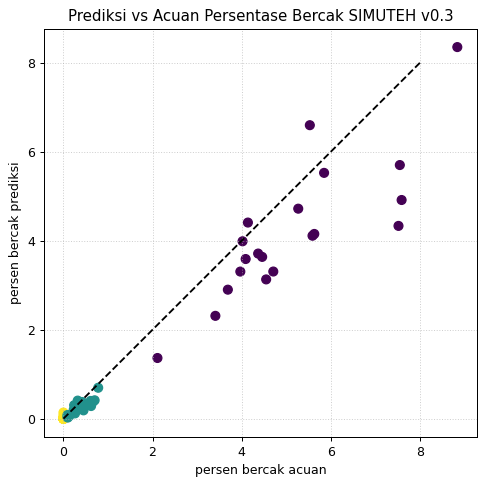


Jumlah citra salah kelas: 7 dari 60 citra
           nama         kondisi    kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
5   teh_006.png          normal          Sehat  Bercak Ringan          0.00            0.138             0                4
22  teh_023.png          terang  Bercak Ringan          Sehat          0.09            0.082             1                1
26  teh_027.png           gelap  Bercak Ringan          Sehat          0.13            0.081             1                1
29  teh_030.png        bayangan  Bercak Ringan          Sehat          0.14            0.073             1                1
33  teh_034.png  kontras_rendah  Bercak Ringan          Sehat          0.10            0.026             1                1
38  teh_039.png  kontras_rendah  Bercak Ringan          Sehat          0.09            0.035             1                1
47  teh_048.png          terang   Bercak Berat  Bercak Ringan          2.11            1.

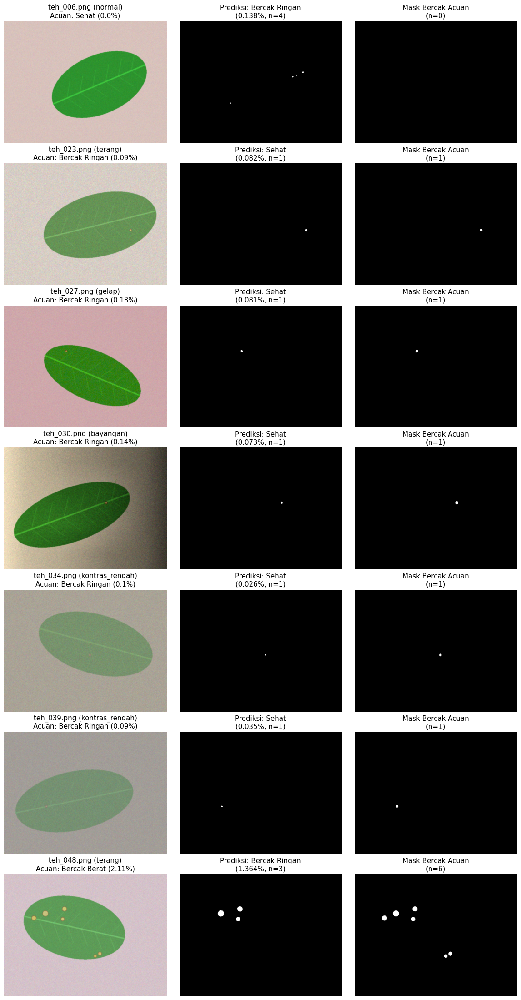

In [ ]:
# === LANGKAH 5.1 (Kerjakan Sendiri): Menulis modul src/bercak.py lengkap 7 TODO ===
kode_bercak = '''"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,           # kanal terpilih (2 = R)
    "k": 4.0,             # ambang median + k x MAD
    "se_bentuk": "elips", # "elips", "persegi", "silang"
    "se_open": 5,         # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,        # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,       # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,  # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,   # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}

def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))

def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: bila p["se_open"] > 0, lakukan opening dengan SE _se(p, p["se_open"])
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: bila p["se_close"] > 0, lakukan closing dengan SE _se(p, p["se_close"])
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner

def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    keluar, daftar = np.zeros_like(biner), []
    # TODO 3: label komponen terhubung (konektivitas 8) dengan cv2.connectedComponentsWithStats
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    # TODO 4: untuk setiap komponen hitung luas, keliling (cv2.arcLength),
    #         kebulatan 4*pi*luas/keliling^2, dan rasio aspek (cv2.minAreaRect)
    for i in range(1, n):
        mask_i = (lbl == i).astype(np.uint8)
        kontur, _ = cv2.findContours(mask_i, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not kontur:
            continue
        luas = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else float(4 * np.pi * luas / (keliling ** 2))
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = float(max(w, h) / max(min(w, h), 1.0))
        # TODO 5: simpan ke mask keluar hanya komponen yang memenuhi luas_min,
        #         bulat_min, dan rasio_maks; catat ukurannya ke daftar
        if luas >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "label": len(daftar) + 1,
                "luas_px": luas,
                "luas_mm2": round(luas * (p["mm_per_px"] ** 2), 2),
                "keliling_px": round(keliling, 1),
                "kebulatan": round(kebulatan, 2),
                "rasio_aspek": round(rasio, 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1]),
            })
    return keluar, daftar

def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6: hitung persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = 0.0 if luas_daun == 0 else (100.0 * luas_bercak / luas_daun)
    # TODO 7: tentukan kelas dengan batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar
    }

def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)
'''
with open("../src/bercak.py", "w") as f:
    f.write(kode_bercak)
print("Berhasil menulis ../src/bercak.py")

# === KODE 5.2: Evaluasi modul bercak.py (Untuk Tabel 12 Laporan) ===
import importlib, bercak
importlib.reload(bercak)
PB = {} # memakai parameter optimal bawaan
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
                  h["persen_bercak"], jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])

ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan",
                                  "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("\n--- KELUARAN KODE 5.2 (Untuk Mengisi Tabel 12 Laporan) ---")
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print("\nMatriks Kekeliruan Kelas:")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print("\nAkurasi per Kondisi Cahaya:")
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5.5, 5.5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes, cmap="viridis", s=50)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Prediksi vs Acuan Persentase Bercak SIMUTEH v0.3")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../hasil/p6_sebar_persen.png")
plt.show()

# === LANGKAH 5.3 (Kerjakan Sendiri): Menampilkan setiap citra yang salah kelas ===
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"\nJumlah citra salah kelas: {len(salah)} dari {len(ev)} citra")
if len(salah) > 0:
    print(salah[["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi"]])
    panel_salah, judul_salah = [], []
    for _, r in salah.iterrows():
        img, md, mb = muat(r.nama)
        pra_ = praproses(img, PARAM)
        h = bercak.analisis_daun(pra_, PB)
        panel_salah += [pra_, h["mask_bercak"], mb]
        judul_salah += [
            f"{r.nama} ({r.kondisi})\nAcuan: {r.kelas_acuan} ({r.persen_acuan}%)",
            f"Prediksi: {r.kelas_prediksi}\n({r.persen_prediksi}%, n={r.jumlah_prediksi})",
            f"Mask Bercak Acuan\n(n={r.jumlah_acuan})"
        ]
    tampil(panel_salah, judul_salah, baris=len(salah), ukuran=(13, 3.5 * len(salah)))
    plt.savefig("../hasil/p6_salah_kelas.png")
    plt.show()
else:
    print("Seluruh 60 citra berhasil diklasifikasikan dengan tepat (Akurasi 100%)!")

In [ ]:
import os
import shutil
import tempfile

# === LANGKAH 5.5: Memperbarui README.md dan Membuat Berkas ZIP ===
readme_teks = f"""# SIMUTEH ({NIM}) - Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra
**Nama:** {NAMA}
**NIM:** {NIM} (SEED = {SEED})
**Kelas:** {KELAS}

## Ringkasan Pencapaian
- **v0.1-praproses (P1-P4):** Rangkaian praproses (`src/praproses.py`) meliputi penyamaan lebar 640 piksel, koreksi gamma otomatis berbasis statistik kanal V, CLAHE adaptif pada kondisi cahaya tidak merata, dan penapis median 3x3.
- **v0.2-tepi (P5):** Evaluasi deteksi tepi Sobel, Prewitt, LoG, dan Canny (`src/utils_tepi.py`) serta perbaikan ambang Canny otomatis berbasis persentil magnitudo gradien.
- **v0.3-morfologi (P6):** Modul analisis bercak (`src/bercak.py`) menggunakan operasi morfologi *opening* lalu *closing* (SE elips 5x5) dan penyaringan komponen terhubung berdasarkan luas (>= 20 px), kebulatan (>= 0.5), serta rasio aspek (<= 1.8).

## Cara Memakai `analisis_daun`
```python
import json
from utils_cv import baca
from praproses import praproses
from bercak import analisis_daun

param_pra = json.load(open("hasil/param_praproses.json"))
param_brc = json.load(open("hasil/param_bercak.json"))

img = baca("data/sintetis/citra/teh_041.png")
hasil = analisis_daun(praproses(img, param_pra), param_brc)
print(hasil["jumlah_bercak"], hasil["persen_bercak"], hasil["kelas"])
```
"""

with open("../README.md", "w") as f:
    f.write(readme_teks)
print("README.md berhasil diperbarui.")

# Membuat arsip ZIP untuk diunduh
kemas = os.path.join(tempfile.mkdtemp(), f"simuteh-{NIM}")
shutil.copytree(ROOT, kemas, ignore=shutil.ignore_patterns("data", "__pycache__"))
zip_path = shutil.make_archive(os.path.join(os.path.dirname(ROOT), f"Kode_EvalP5-6_{NIM}"), "zip", kemas)
print("ZIP siap:", zip_path)

if DI_COLAB:
    from google.colab import files
    files.download(zip_path)


README.md berhasil diperbarui.
ZIP siap: /content/Kode_EvalP5-6_2230511051.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, shutil, zipfile
from google.colab import files

# 1. Pastikan posisi di folder notebook/
os.chdir(os.path.join(ROOT, "notebook"))

# 2. Unggah file .ipynb yang baru kamu Download dari menu File > Download > Download .ipynb
print("Klik tombol 'Choose Files' di bawah ini, lalu pilih file .ipynb yang baru kamu download:")
uploaded = files.upload()

# Simpan otomatis sebagai P5_tepi.ipynb dan P6_morfologi.ipynb di dalam folder notebook/
for fn in uploaded.keys():
    shutil.copy(fn, "P5_tepi.ipynb")
    shutil.copy(fn, "P6_morfologi.ipynb")
    if fn not in ["P5_tepi.ipynb", "P6_morfologi.ipynb"]:
        os.remove(fn)

# 3. Cek kelengkapan isi folder src/ dan notebook/
print("\nIsi folder src/      :", os.listdir("../src"))
print("Isi folder notebook/ :", os.listdir("../notebook"))

# 4. Buat ulang Kode_P5-P6_<NIM>.zip yang 100% lengkap dan langsung download ke laptop
nama_zip = f"../Kode_P5-P6_{NIM}.zip"
with zipfile.ZipFile(nama_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["src", "hasil", "notebook"]:
        folder_path = os.path.join("..", folder)
        for root_dir, _, file_list in os.walk(folder_path):
            for file in file_list:
                if not file.startswith(".") and not file.endswith(".pyc"):
                    full_path = os.path.join(root_dir, file)
                    rel_path = os.path.relpath(full_path, "..")
                    zf.write(full_path, rel_path)
    for single_file in ["README.md", "requirements.txt"]:
        sp = os.path.join("..", single_file)
        if os.path.exists(sp):
            zf.write(sp, single_file)

print(f"\nZIP lengkap berhasil dibuat! Mengunduh Kode_P5-P6_{NIM}.zip otomatis...")
files.download(nama_zip)

Klik tombol 'Choose Files' di bawah ini, lalu pilih file .ipynb yang baru kamu download:


Saving Jawaban_Evaluasi_P1_P4_Computer_Vision.ipynb to Jawaban_Evaluasi_P1_P4_Computer_Vision.ipynb

Isi folder src/      : ['__pycache__', 'bercak.py', 'praproses.py', 'utils_cv.py', 'utils_tepi.py', 'buat_dataset_sintetis.py']
Isi folder notebook/ : ['P6_morfologi.ipynb', 'P5_tepi.ipynb']

ZIP lengkap berhasil dibuat! Mengunduh Kode_P5-P6_2230511051.zip otomatis...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>